<a href="https://colab.research.google.com/github/Euripedes357/GMSF/blob/main/C%C3%B3pia_de_USP_Deep_Learning_Euripedes_Documentado_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predição de Preços de Imóveis
## Avaliação crítica de uma rede neural e comparação de três alternativas
### MLP regularizada · Elastic Net · CatBoost

**Autor:** Euripedes Gomes  
**Contexto acadêmico:** Modelagem de Dados e Deep Learning — USP  
**Data da execução documentada:** 10 de outubro de 2026

**Fonte dos dados — Kaggle:** [House Prices Dataset, lespin](https://www.kaggle.com/datasets/lespin/house-prices-dataset)  
**Referência didática:** [Redes Neurais — Aula 01, Welton Dionisio](https://github.com/weltondionisio/USP_Redes_Neurais_Artificiais/blob/main/Redes_Neurais_Aula_01.ipynb)

> **Pergunta de pesquisa:** é possível reduzir os erros de previsão de preços de imóveis ao corrigir o protocolo de preparação e comparar uma rede neural regularizada, uma regressão Elastic Net e um modelo de boosting de árvores?

**Resumo.** Este projeto usa 1.460 imóveis com preço conhecido, separando 934 para treino, 234 para validação e 292 para teste. Uma referência com arquitetura 128/64 é comparada a três propostas. No teste, todas reduziram MAE e RMSE em relação à referência. A MLP regularizada reduziu o MAE em 15,02%, com 54,19% menos parâmetros; o Elastic Net apresentou o menor RMSE observado, 23.572,41, uma redução de 27,50%. O CatBoost liderou na validação, mas não no teste. Os achados se limitam a uma divisão dos dados e não constituem prova de superioridade estatística.

**Como ler.** Cada etapa numerada corresponde a uma célula de código, com objetivo, explicação dos comandos e interpretação. A numeração 01–32 é fixa por ordem de leitura; números entre colchetes do Colab são contadores de execução e podem mudar. Códigos, gráficos, tabelas e saídas da execução recebida foram preservados. Esta edição acrescenta documentação; não reexecuta os treinamentos.

## Índice por comando

[Objetivo e método](#scrollTo=doc-metodo) · [Conclusão final](#scrollTo=doc-conclusao)

| Etapa | Comando / célula | Execução na cópia recebida |
|---|---|---:|
| 01 | [Importação da base House Prices](#scrollTo=doc-etapa-01) | [1] |
| 02 | [Gráfico da quantidade de imóveis](#scrollTo=doc-etapa-02) | [10] |
| 03 | [Diagnóstico inicial de tipos, identificadores e ausências](#scrollTo=doc-etapa-03) | [3] |
| 04 | [Gráficos de tipos de dados e valores ausentes](#scrollTo=doc-etapa-04) | [11] |
| 05 | [Leitura do dicionário de dados](#scrollTo=doc-etapa-05) | [4] |
| 06 | [Consulta às definições das variáveis selecionadas](#scrollTo=doc-etapa-06) | [5] |
| 07 | [Tabela explicativa do dicionário](#scrollTo=doc-etapa-07) | [12] |
| 08 | [Verificação semântica de lareira e garagem](#scrollTo=doc-etapa-08) | [6] |
| 09 | [Gráfico de confirmação da ausência de recursos](#scrollTo=doc-etapa-09) | [14] |
| 10 | [Tratamento inicial de ausências estruturais](#scrollTo=doc-etapa-10) | [7] |
| 11 | [Separação entre treino, validação e teste](#scrollTo=doc-etapa-11) | [8] |
| 12 | [Definição das entradas X e do alvo y](#scrollTo=doc-etapa-12) | [9] |
| 13 | [Tabela de conferência dos conjuntos](#scrollTo=doc-etapa-13) | [15] |
| 14 | [Diagnóstico de ausências somente no treino](#scrollTo=doc-etapa-14) | [16] |
| 15 | [Gráfico das ausências no treino](#scrollTo=doc-etapa-15) | [17] |
| 16 | [Matriz de correlação de Pearson](#scrollTo=doc-etapa-16) | [18] |
| 17 | [Boxplots e violinos das distribuições](#scrollTo=doc-etapa-17) | [19] |
| 18 | [Correção do tipo de MSSubClass](#scrollTo=doc-etapa-18) | [20] |
| 19 | [Regras para garagem e piscina](#scrollTo=doc-etapa-19) | [21] |
| 20 | [Regras para ausência de porão](#scrollTo=doc-etapa-20) | [22] |
| 21 | [Imputação numérica e indicadores de ausência](#scrollTo=doc-etapa-21) | [23] |
| 22 | [Tratamento das categorias restantes](#scrollTo=doc-etapa-22) | [24] |
| 23 | [Recuperação do significado de MasVnrType](#scrollTo=doc-etapa-23) | [25] |
| 24 | [Padronização e codificação das entradas](#scrollTo=doc-etapa-24) | [26] |
| 25 | [Desenho da arquitetura de referência](#scrollTo=doc-etapa-25) | [27] |
| 26 | [Treinamento e validação da rede de referência](#scrollTo=doc-etapa-26) | [28] |
| 27 | [Curvas de aprendizagem da referência](#scrollTo=doc-etapa-27) | [29] |
| 28 | [Quantificação da piora após a melhor época](#scrollTo=doc-etapa-28) | [30] |
| 29 | [Alternativa 1 — MLP regularizada com preço em log](#scrollTo=doc-etapa-29) | [31] |
| 30 | [Alternativa 2 — Elastic Net e seleção da regularização](#scrollTo=doc-etapa-30) | [32] |
| 31 | [Alternativa 3 — CatBoost com categorias preservadas](#scrollTo=doc-etapa-31) | [33] |
| 32 | [Avaliação final nos 292 imóveis de teste](#scrollTo=doc-etapa-32) | [34] |

Os links usam IDs das células para navegação no Colab. Os títulos também permitem navegar pelo sumário lateral. Os números de execução foram mantidos como referência histórica; não indicam a ordem que você deve seguir.

## Objetivo, avaliação crítica e desenho experimental

O desafio é propor alternativas ao trabalho de referência e justificar as decisões com evidências. O projeto compara **procedimentos completos**, incluindo representação do alvo e preparação apropriada a cada modelo; não isola causalmente o efeito de um único hiperparâmetro.

### Oportunidades identificadas na análise inicial

A avaliação inicial do código didático, realizada durante o desenvolvimento, orientou as medidas abaixo. Ela não deve ser apresentada como auditoria exaustiva ou inventário de todas as melhorias possíveis.

| Tema | Risco discutido | Tratamento implementado neste projeto |
|---|---|---|
| Preparação antes da divisão | Estatísticas da amostra de avaliação influenciarem o ajuste | Medianas, escalas e vocabulário de categorias aprendidos somente no treino |
| Escalas recalculadas em outro conjunto | Entradas de avaliação incompatíveis com o modelo treinado | Reutilização do mesmo transformador com `transform` |
| Exclusão ou preenchimento genérico de ausências | Perder a distinção entre inexistência de recurso e informação desconhecida | Regras do dicionário, conferência por linha e categorias explícitas |
| Códigos armazenados como números | Impor relações quantitativas a categorias | Conversão de `MSSubClass` para texto |
| Treinamento prolongado | Melhorar o ajuste ao treino e piorar a validação | Curvas de aprendizagem e EarlyStopping na proposta MLP |
| Comparação entre execuções | Confundir efeito do algoritmo com diferença de amostras | Mesmas linhas de treino, validação e teste em todos os modelos |

**Escopo da referência.** O experimento implementa a arquitetura inicial 128/64 do professor com nossa preparação e validação. Não é reprodução integral do notebook original. Os percentuais finais comparam as alternativas a essa referência corrigida, não diretamente aos números históricos apresentados pelo professor.

### Protocolo efetivamente executado

1. Inspeção descritiva inicial da base completa e interpretação do dicionário; regras semânticas por linha.
2. Divisão aleatória com semente 42: treino 934, validação 234 e teste 292.
3. Exploração de correlações e distribuições no treino; imputação e codificação ajustadas no treino.
4. Ajuste da referência e das alternativas; seleção de parâmetros/épocas usando a validação.
5. Escolha preliminar de CatBoost pelo resultado de validação e avaliação dos quatro modelos fixos no teste.

**Nuance sobre isolamento.** O teste ficou reservado para a avaliação preditiva final, mas tipos e ausências da base inteira foram inspecionados no início. As regras anteriores à divisão são determinísticas e não usam o preço para aprender parâmetros. Um desenho ainda mais estrito reservaria o teste antes de toda exploração. Não houve uso dos preços do teste para ajuste dos modelos ou seleção das configurações aqui executadas.

### Métricas e transformações

Para erro \(e_i = y_i - \hat y_i\):

\[
MAE = \frac{1}{n}\sum_i |e_i|,\quad
MSE = \frac{1}{n}\sum_i e_i^2,\quad
RMSE = \sqrt{MSE},\quad
R^2 = 1 - \frac{\sum_i e_i^2}{\sum_i(y_i-\bar y)^2}.
\]

MAE e RMSE estão na unidade do preço; MSE está nessa unidade ao quadrado. R² mede redução do erro quadrático em relação a prever a média da amostra de avaliação; não é percentual de acertos. Menores MAE/RMSE e maior R² são preferíveis, mas as métricas podem ordenar modelos de forma diferente.

As alternativas usam \(z=\ln(1+y)\). A MLP também padroniza z com média e desvio do treino. A transformação inversa é \(y=\exp(z)-1\). Treinar em log privilegia outra estrutura de erros; a transformação inversa simples não assegura uma estimativa não viesada da média do preço. Nenhuma correção de retrans formação foi aplicada nesta execução.

**Critérios de seleção distintos:** MLP e CatBoost monitoram erro na escala transformada; Elastic Net é escolhido pelo RMSE monetário de validação entre 12 configurações. A comparação é de propostas com diferentes orçamentos e critérios de ajuste, não de algoritmos submetidos a uma busca idêntica.

## 01. Importação da base House Prices

**Objetivo.** Disponibilizar os arquivos do Kaggle e carregar os imóveis com preço conhecido.

**Como os comandos funcionam.** `%pip install -q kagglehub` instala o acesso ao Kaggle; `import` disponibiliza bibliotecas; `Path` representa caminhos. `dataset_download` obtém a base, e `pd.read_csv` transforma o CSV em um DataFrame chamado `df_original`. `shape` informa linhas e colunas; `head()` mostra as primeiras linhas; `display()` apresenta a tabela.

**Leitura do resultado e cuidados.** A execução carregou 1.460 imóveis e 81 colunas: 79 características, o identificador `Id` e o alvo `SalePrice`. O arquivo externo `test.csv` do Kaggle não tem o alvo conhecido e não é o teste de 292 imóveis usado neste estudo. A leitura inicial pode interpretar o texto `None` como ausência; isso será corrigido para `MasVnrType` na etapa 23.

In [ ]:
# 1. Instalar a ferramenta de acesso ao Kaggle
%pip install -q kagglehub

# 2. Importar as bibliotecas
import kagglehub
import pandas as pd
from pathlib import Path

# 3. Baixar a mesma base utilizada pelo professor
pasta = Path(
    kagglehub.dataset_download("lespin/house-prices-dataset")
)

# 4. Carregar os dados com preços conhecidos
df_original = pd.read_csv(pasta / "train.csv")

# 5. Conferir o tamanho e visualizar os primeiros imóveis
print(f"Quantidade de imóveis: {df_original.shape[0]}")
print(f"Quantidade de colunas: {df_original.shape[1]}")

display(df_original.head())

Using Colab cache for faster access to the 'house-prices-dataset' dataset.
Quantidade de imóveis: 1460
Quantidade de colunas: 81


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## 02. Gráfico da quantidade de imóveis

**Objetivo.** Registrar visualmente o tamanho da base importada.

**Como os comandos funcionam.** `len(df_original)` conta linhas. `plt.subplots` cria figura e eixo; `ax.bar` desenha a barra e `bar_label` escreve a quantidade. `set_title`, `set_ylabel` e `set_ylim` configuram a apresentação; `tight_layout` ajusta margens e `show` exibe.

**Leitura do resultado e cuidados.** A barra representa 1.460 registros. É uma conferência descritiva de volume, não uma comparação entre bairros ou tipos de imóvel. Os demais gráficos detalham a composição e a qualidade dos dados.

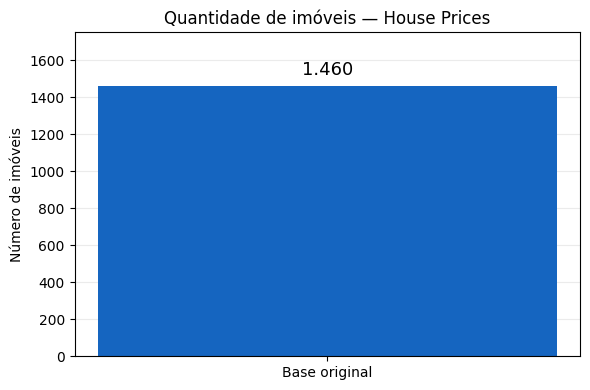

In [ ]:
import matplotlib.pyplot as plt

# Contar os imóveis carregados
quantidade = len(df_original)

fig, ax = plt.subplots(figsize=(6, 4))

barras = ax.bar(
    ["Base original"],
    [quantidade],
    color="#1565C0",
    width=0.4
)

# Escrever a quantidade acima da barra
ax.bar_label(
    barras,
    labels=[f"{quantidade:,}".replace(",", ".")],
    padding=5,
    fontsize=13
)

ax.set_title("Quantidade de imóveis — House Prices")
ax.set_ylabel("Número de imóveis")
ax.set_ylim(0, quantidade * 1.20)
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

## 03. Diagnóstico inicial de tipos, identificadores e ausências

**Objetivo.** Verificar estrutura e problemas de qualidade antes do tratamento.

**Como os comandos funcionam.** `dtypes.value_counts()` resume os tipos de armazenamento. `duplicated().sum()` conta IDs repetidos; `isna().sum()` conta ausências. A divisão pela quantidade de linhas produz percentuais. `pd.DataFrame` reúne as medidas e `sort_values` ordena as colunas mais afetadas.

**Leitura do resultado e cuidados.** Foram observadas 43 colunas de texto, 35 inteiras e 3 de ponto flutuante, incluindo alvo e ID. Não há IDs repetidos nem preços ausentes na base carregada. IDs distintos não garantem ausência de registros semanticamente duplicados. Uma alta taxa de NaN não é motivo suficiente para excluir uma variável.

In [ ]:
# Conferir os tipos de dados presentes na tabela
print("TIPOS DE DADOS:")
print(df_original.dtypes.value_counts())

# Verificar identificadores repetidos
print("\nIDs repetidos:", df_original["Id"].duplicated().sum())

# Verificar se há imóveis sem preço informado
print("Preços ausentes:", df_original["SalePrice"].isna().sum())

# Contar valores ausentes por coluna
ausentes = df_original.isna().sum()

# Organizar o diagnóstico em uma tabela
resumo_ausentes = pd.DataFrame({
    "Quantidade ausente": ausentes,
    "Percentual (%)": (ausentes / len(df_original) * 100).round(2)
})

# Mostrar somente colunas com valores ausentes
display(
    resumo_ausentes[resumo_ausentes["Quantidade ausente"] > 0]
    .sort_values("Quantidade ausente", ascending=False)
)

TIPOS DE DADOS:
object     43
int64      35
float64     3
Name: count, dtype: int64

IDs repetidos: 0
Preços ausentes: 0


,Quantidade ausente,Percentual (%)
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
MasVnrType,872,59.73
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageType,81,5.55
GarageYrBlt,81,5.55
GarageFinish,81,5.55


## 04. Gráficos de tipos de dados e valores ausentes

**Objetivo.** Facilitar a comparação entre tipos de coluna e entre percentuais de ausência.

**Como os comandos funcionam.** `astype(str)` converte os nomes dos tipos em rótulos; `value_counts` conta cada tipo. `isna().mean() * 100` calcula a proporção de ausências porque verdadeiro equivale a 1. `barh` gera barras horizontais e `invert_yaxis` coloca os maiores valores no topo.

**Leitura do resultado e cuidados.** O gráfico de ausências antecede o tratamento e reflete a interpretação inicial do CSV. Algumas ausências indicam inexistência de piscina, cerca ou outro recurso; outras significam informação desconhecida. A leitura do dicionário orienta essa distinção.

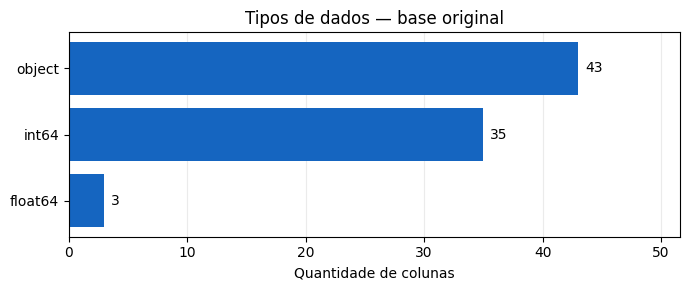

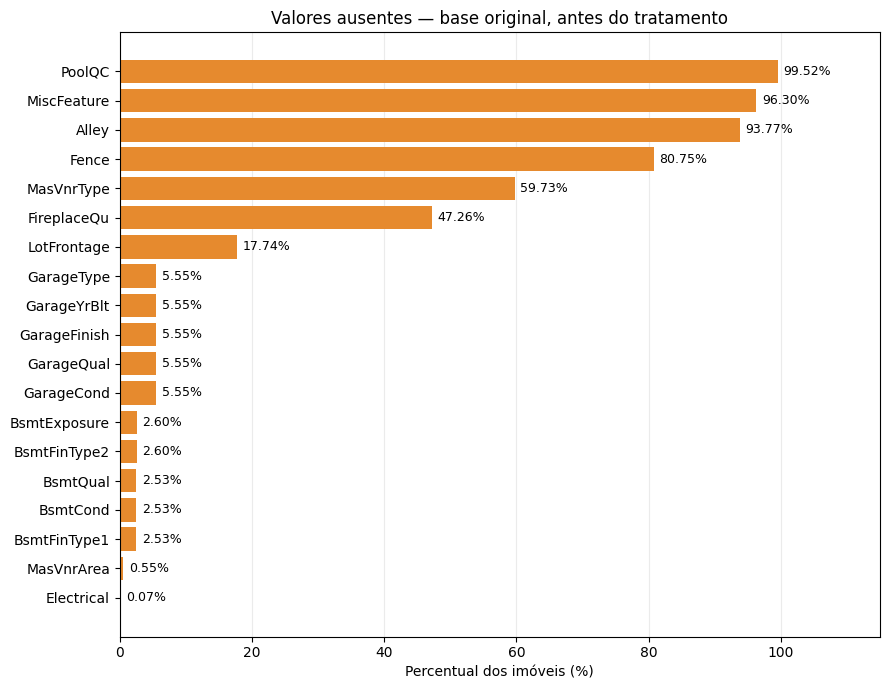

In [ ]:
import matplotlib.pyplot as plt

# Gráfico 1 — tipos de dados das 81 colunas
tipos = df_original.dtypes.astype(str).value_counts()

fig, ax = plt.subplots(figsize=(7, 3))

barras = ax.barh(
    tipos.index,
    tipos.values,
    color="#1565C0"
)

ax.bar_label(barras, padding=5)
ax.invert_yaxis()
ax.set_title("Tipos de dados — base original")
ax.set_xlabel("Quantidade de colunas")
ax.set_xlim(0, tipos.max() * 1.20)
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

# Gráfico 2 — percentual de valores ausentes por coluna
percentuais = df_original.isna().mean() * 100
percentuais = percentuais[percentuais > 0].sort_values(
    ascending=False
)

fig, ax = plt.subplots(figsize=(9, 7))

barras = ax.barh(
    percentuais.index,
    percentuais.values,
    color="#E68A2E"
)

ax.bar_label(barras, fmt="%.2f%%", padding=4, fontsize=9)
ax.invert_yaxis()
ax.set_title("Valores ausentes — base original, antes do tratamento")
ax.set_xlabel("Percentual dos imóveis (%)")
ax.set_xlim(0, 115)
ax.set_xticks(range(0, 101, 20))
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

## 05. Leitura do dicionário de dados

**Objetivo.** Consultar os significados oficiais das variáveis e de seus códigos.

**Como os comandos funcionam.** `pasta.iterdir()` lista os arquivos; `sorted` organiza a listagem. `exists()` verifica a presença de `data_description.txt`; `read_text` lê seu conteúdo. `encoding="utf-8"` define a codificação, e `errors="replace"` substitui caracteres que não puderem ser decodificados.

**Leitura do resultado e cuidados.** O dicionário serve de base para as regras semânticas. Na execução registrada ele estava disponível. As próximas consultas dependem da variável `descricao`; se o arquivo não existir em uma nova execução, essa dependência deve ser resolvida antes de continuar.

In [ ]:
# Listar os arquivos disponíveis na pasta baixada do Kaggle
for arquivo in sorted(pasta.iterdir()):
    print(arquivo.name)

# Exibir o dicionário dos dados, caso esteja disponível
dicionario = pasta / "data_description.txt"

if dicionario.exists():
    descricao = dicionario.read_text(
        encoding="utf-8",
        errors="replace"
    )
    print("\nDICIONÁRIO DOS DADOS:\n")
    print(descricao)
else:
    print("\nO dicionário não foi encontrado nesta pasta.")

data_description.txt
sample_submission.csv
test.csv
train.csv

DICIONÁRIO DOS DADOS:

MSSubClass: Identifies the type of dwelling involved in the sale.	

        20	1-STORY 1946 & NEWER ALL STYLES
        30	1-STORY 1945 & OLDER
        40	1-STORY W/FINISHED ATTIC ALL AGES
        45	1-1/2 STORY - UNFINISHED ALL AGES
        50	1-1/2 STORY FINISHED ALL AGES
        60	2-STORY 1946 & NEWER
        70	2-STORY 1945 & OLDER
        75	2-1/2 STORY ALL AGES
        80	SPLIT OR MULTI-LEVEL
        85	SPLIT FOYER
        90	DUPLEX - ALL STYLES AND AGES
       120	1-STORY PUD (Planned Unit Development) - 1946 & NEWER
       150	1-1/2 STORY PUD - ALL AGES
       160	2-STORY PUD - 1946 & NEWER
       180	PUD - MULTILEVEL - INCL SPLIT LEV/FOYER
       190	2 FAMILY CONVERSION - ALL STYLES AND AGES

MSZoning: Identifies the general zoning classification of the sale.
		
       A	Agriculture
       C	Commercial
       FV	Floating Village Residential
       I	Industrial
       RH	Residential High Densi

## 06. Consulta às definições das variáveis selecionadas

**Objetivo.** Extrair do dicionário os campos importantes para interpretar as ausências.

**Como os comandos funcionam.** `re.split` separa o documento em blocos, reconhecendo cabeçalhos no formato `Variavel:`. A lista `variaveis` define os campos de interesse. Os laços `for` percorrem variáveis e blocos; `startswith` identifica a definição correta e `break` encerra a busca daquele campo.

**Leitura do resultado e cuidados.** A consulta inclui `PoolQC`, `MiscFeature`, `Alley`, `Fence`, `MasVnrType`, `FireplaceQu`, `LotFrontage` e `GarageType`. Ela não elimina características do modelo: apenas seleciona trechos do dicionário para inspeção.

In [ ]:
import re

# Variáveis que queremos consultar no dicionário
variaveis = [
    "PoolQC", "MiscFeature", "Alley", "Fence",
    "MasVnrType", "FireplaceQu", "LotFrontage",
    "GarageType"
]

# Separar o documento em blocos, um para cada variável
blocos = re.split(r"(?m)(?=^[A-Za-z][A-Za-z0-9]*:)", descricao)

# Exibir somente as definições selecionadas
for variavel in variaveis:
    for bloco in blocos:
        if bloco.startswith(variavel + ":"):
            print(bloco.strip())
            print()
            break

PoolQC: Pool quality
		
       Ex	Excellent
       Gd	Good
       TA	Average/Typical
       Fa	Fair
       NA	No Pool

MiscFeature: Miscellaneous feature not covered in other categories
		
       Elev	Elevator
       Gar2	2nd Garage (if not described in garage section)
       Othr	Other
       Shed	Shed (over 100 SF)
       TenC	Tennis Court
       NA	None

Alley: Type of alley access to property

       Grvl	Gravel
       Pave	Paved
       NA 	No alley access

Fence: Fence quality
		
       GdPrv	Good Privacy
       MnPrv	Minimum Privacy
       GdWo	Good Wood
       MnWw	Minimum Wood/Wire
       NA	No Fence

MasVnrType: Masonry veneer type

       BrkCmn	Brick Common
       BrkFace	Brick Face
       CBlock	Cinder Block
       None	None
       Stone	Stone

FireplaceQu: Fireplace quality

       Ex	Excellent - Exceptional Masonry Fireplace
       Gd	Good - Masonry Fireplace in main level
       TA	Average - Prefabricated Fireplace in main living area or Masonry Fireplace in basement
   

## 07. Tabela explicativa do dicionário

**Objetivo.** Apresentar descrição, códigos e quantidade de ausências em uma tabela legível.

**Como os comandos funcionam.** `splitlines()` separa as linhas de cada definição; `split(":", 1)` extrai o texto após o nome. `append` acumula os registros em `linhas`. `DataFrame.style` permite ocultar o índice, adicionar legenda, preservar quebras de linha e definir cores e alinhamento.

**Leitura do resultado e cuidados.** A tabela mantém as descrições originais em inglês e mostra a contagem inicial de ausências. A formatação melhora a leitura, mas não modifica os dados utilizados pelos modelos.

In [ ]:
import pandas as pd

# Organizar os trechos do dicionário em uma tabela
linhas = []

for variavel in variaveis:
    for bloco in blocos:
        if bloco.startswith(variavel + ":"):
            partes = bloco.strip().splitlines()

            definicao = partes[0].split(":", 1)[1].strip()
            codigos = "\n".join(
                linha.strip()
                for linha in partes[1:]
                if linha.strip()
            )

            linhas.append({
                "Variável": variavel,
                "Descrição original": definicao,
                "Códigos e significados": codigos or "Sem códigos listados",
                "Ausentes na base original": int(
                    df_original[variavel].isna().sum()
                )
            })
            break

tabela_dicionario = pd.DataFrame(linhas)

# Formatar a tabela para facilitar a leitura
display(
    tabela_dicionario.style
    .hide(axis="index")
    .set_caption("Dicionário das variáveis selecionadas")
    .set_properties(**{
        "text-align": "left",
        "white-space": "pre-wrap",
        "vertical-align": "top",
        "padding": "10px"
    })
    .set_table_styles([{
        "selector": "th",
        "props": [
            ("background-color", "#1565C0"),
            ("color", "white"),
            ("text-align", "left")
        ]
    }])
)

Variável,Descrição original,Códigos e significados,Ausentes na base original
PoolQC,Pool quality,Ex Excellent Gd Good TA Average/Typical Fa Fair NA No Pool,1453
MiscFeature,Miscellaneous feature not covered in other categories,Elev Elevator Gar2 2nd Garage (if not described in garage section) Othr Other Shed Shed (over 100 SF) TenC Tennis Court NA None,1406
Alley,Type of alley access to property,Grvl Gravel Pave Paved NA No alley access,1369
Fence,Fence quality,GdPrv Good Privacy MnPrv Minimum Privacy GdWo Good Wood MnWw Minimum Wood/Wire NA No Fence,1179
MasVnrType,Masonry veneer type,BrkCmn Brick Common BrkFace Brick Face CBlock Cinder Block None None Stone Stone,872
FireplaceQu,Fireplace quality,Ex Excellent - Exceptional Masonry Fireplace Gd Good - Masonry Fireplace in main level TA Average - Prefabricated Fireplace in main living area or Masonry Fireplace in basement Fa Fair - Prefabricated Fireplace in basement Po Poor - Ben Franklin Stove NA No Fireplace,690
LotFrontage,Linear feet of street connected to property,Sem códigos listados,259
GarageType,Garage location,2Types More than one type of garage Attchd Attached to home Basment Basement Garage BuiltIn Built-In (Garage part of house - typically has room above garage) CarPort Car Port Detchd Detached from home NA No Garage,81


## 08. Verificação semântica de lareira e garagem

**Objetivo.** Verificar se uma informação ausente corresponde à inexistência do recurso.

**Como os comandos funcionam.** `loc[mascara, coluna]` seleciona uma coluna apenas nas linhas em que a condição é verdadeira. `FireplaceQu.isna()` e `GarageType.isna()` definem os grupos; `value_counts(dropna=False)` conta os valores de `Fireplaces` e `GarageCars`, incluindo eventuais ausências.

**Leitura do resultado e cuidados.** Os 690 imóveis com qualidade de lareira ausente têm zero lareiras; os 81 com tipo de garagem ausente têm zero vagas. Essa concordância, junto ao dicionário, fundamenta rótulos de ausência do recurso. A contagem se refere à base completa nesta etapa inicial.

In [ ]:
# Conferir a quantidade de lareiras quando a qualidade está ausente
print("QUANTIDADE DE LAREIRAS QUANDO FireplaceQu ESTÁ AUSENTE:")
display(
    df_original.loc[
        df_original["FireplaceQu"].isna(), "Fireplaces"
    ].value_counts(dropna=False).rename("Quantidade de imóveis")
)

# Conferir a capacidade da garagem quando seu tipo está ausente
print("\nVAGAS DE GARAGEM QUANDO GarageType ESTÁ AUSENTE:")
display(
    df_original.loc[
        df_original["GarageType"].isna(), "GarageCars"
    ].value_counts(dropna=False).rename("Quantidade de imóveis")
)

QUANTIDADE DE LAREIRAS QUANDO FireplaceQu ESTÁ AUSENTE:


,Quantidade de imóveis
Fireplaces,
0,690



VAGAS DE GARAGEM QUANDO GarageType ESTÁ AUSENTE:


,Quantidade de imóveis
GarageCars,
0,81


## 09. Gráfico de confirmação da ausência de recursos

**Objetivo.** Mostrar a proporção de registros que confirma a inexistência de lareira e garagem.

**Como os comandos funcionam.** `eq(0)` identifica quantidade zero; a soma dividida pelo tamanho de cada grupo produz o percentual. `zip` combina contagens e percentuais para montar rótulos. `barh` representa os dois grupos e `label_type="center"` coloca as anotações dentro das barras.

**Leitura do resultado e cuidados.** As duas proporções são 100% dentro dos respectivos grupos com informação ausente. Isso não significa que 100% de todos os imóveis estejam sem lareira ou garagem; o denominador é o grupo selecionado.

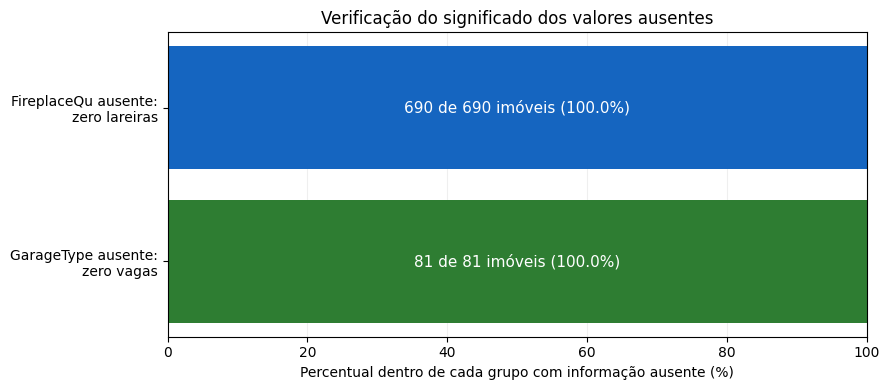

In [ ]:
import matplotlib.pyplot as plt

# Selecionar os registros com informação ausente
lareira = df_original.loc[
    df_original["FireplaceQu"].isna(), "Fireplaces"
]
garagem = df_original.loc[
    df_original["GarageType"].isna(), "GarageCars"
]

# Calcular a proporção que confirma ausência do recurso
grupos = [lareira, garagem]
percentuais = [
    grupo.eq(0).sum() / len(grupo) * 100
    for grupo in grupos
]

rotulos = [
    f"{grupo.eq(0).sum()} de {len(grupo)} imóveis ({pct:.1f}%)"
    for grupo, pct in zip(grupos, percentuais)
]

fig, ax = plt.subplots(figsize=(9, 4))

barras = ax.barh(
    ["FireplaceQu ausente:\nzero lareiras",
     "GarageType ausente:\nzero vagas"],
    percentuais,
    color=["#1565C0", "#2E7D32"]
)

ax.bar_label(
    barras,
    labels=rotulos,
    label_type="center",
    color="white",
    fontsize=11
)

ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("Percentual dentro de cada grupo com informação ausente (%)")
ax.set_title("Verificação do significado dos valores ausentes")
ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.20)

plt.tight_layout()
plt.show()

## 10. Tratamento inicial de ausências estruturais

**Objetivo.** Criar uma base de trabalho e aplicar regras determinísticas por imóvel.

**Como os comandos funcionam.** `copy()` preserva a base original. O operador `&` combina a condição de categoria ausente com a quantidade zero. A atribuição por `loc` preenche somente as linhas confirmadas com `Sem lareira` ou `Sem garagem`. As contagens finais verificam o efeito.

**Leitura do resultado e cuidados.** As regras não calculam médias, medianas ou relações com o preço. Por isso podem ser aplicadas linha a linha antes da divisão. Mesmo assim, a inspeção descritiva inicial foi feita na base completa; não se deve descrever o fluxo como um teste inteiramente invisível desde o primeiro contato com os dados.

In [ ]:
# Criar uma cópia para preparar os dados
df_trabalho = df_original.copy()

# Identificar ausência de lareira confirmada pela quantidade zero
sem_lareira = (
    df_trabalho["FireplaceQu"].isna()
    & (df_trabalho["Fireplaces"] == 0)
)

df_trabalho.loc[sem_lareira, "FireplaceQu"] = "Sem lareira"

# Identificar ausência de garagem confirmada pela quantidade zero
sem_garagem = (
    df_trabalho["GarageType"].isna()
    & (df_trabalho["GarageCars"] == 0)
)

df_trabalho.loc[sem_garagem, "GarageType"] = "Sem garagem"

# Conferir as alterações
print("Registros classificados como sem lareira:", sem_lareira.sum())
print("Registros classificados como sem garagem:", sem_garagem.sum())

print("\nAusências restantes nessas duas colunas:")
print(df_trabalho[["FireplaceQu", "GarageType"]].isna().sum())

Registros classificados como sem lareira: 690
Registros classificados como sem garagem: 81

Ausências restantes nessas duas colunas:
FireplaceQu    0
GarageType     0
dtype: int64


## 11. Separação entre treino, validação e teste

**Objetivo.** Definir amostras distintas para ajuste, seleção de configurações e avaliação final.

**Como os comandos funcionam.** `train_test_split(test_size=0.20, random_state=42)` primeiro reserva 20% para teste. Uma segunda divisão retira 20% dos 80% restantes para validação. `random_state` fixa a aleatoriedade dessa separação; `len` confere os tamanhos.

**Leitura do resultado e cuidados.** Resultado: 934 imóveis de treino, 234 de validação e 292 de teste; aproximadamente 64%, 16% e 20%. A divisão é aleatória, sem estratificação por preço, controle espacial ou temporal. A validade das conclusões está limitada a esse desenho.

In [ ]:
from sklearn.model_selection import train_test_split

# Reservar 20% dos imóveis para o teste final
dados_treino_val, dados_teste = train_test_split(
    df_trabalho,
    test_size=0.20,
    random_state=42
)

# Separar o restante entre treino e validação
dados_treino, dados_validacao = train_test_split(
    dados_treino_val,
    test_size=0.20,
    random_state=42
)

print("Imóveis para treino:", len(dados_treino))
print("Imóveis para validação:", len(dados_validacao))
print("Imóveis para teste:", len(dados_teste))

Imóveis para treino: 934
Imóveis para validação: 234
Imóveis para teste: 292


## 12. Definição das entradas X e do alvo y

**Objetivo.** Separar as características utilizadas na previsão do preço que será previsto.

**Como os comandos funcionam.** `drop(columns=["Id", "SalePrice"])` cria as entradas sem o identificador e sem o alvo. A seleção `["SalePrice"].copy()` cria cada vetor de preços. `shape` verifica a quantidade de linhas e características.

**Leitura do resultado e cuidados.** Os três conjuntos têm 79 características antes de indicadores e codificação. O alvo não entra em X, evitando vazamento direto do preço. Os índices originais são preservados, permitindo recuperar corretamente dados de cada imóvel mais adiante.

In [ ]:
# Entradas: características usadas para prever o preço
X_treino = dados_treino.drop(columns=["Id", "SalePrice"])
X_validacao = dados_validacao.drop(columns=["Id", "SalePrice"])
X_teste = dados_teste.drop(columns=["Id", "SalePrice"])

# Alvo: preço de venda que o modelo aprenderá a prever
y_treino = dados_treino["SalePrice"].copy()
y_validacao = dados_validacao["SalePrice"].copy()
y_teste = dados_teste["SalePrice"].copy()

# Conferir a quantidade de imóveis e características
print("X_treino:", X_treino.shape)
print("X_validacao:", X_validacao.shape)
print("X_teste:", X_teste.shape)
print("Quantidade de preços para treino:", len(y_treino))

X_treino: (934, 79)
X_validacao: (234, 79)
X_teste: (292, 79)
Quantidade de preços para treino: 934


## 13. Tabela de conferência dos conjuntos

**Objetivo.** Documentar a compatibilidade entre as entradas e os preços de cada amostra.

**Como os comandos funcionam.** `pd.DataFrame` organiza os tamanhos de X e y. `shape[1]` conta as características; `len` conta registros. O objeto `style` aplica legenda, alinhamento e cores para apresentação.

**Leitura do resultado e cuidados.** Treino, validação e teste devem ter a mesma quantidade de características; em cada conjunto, o número de linhas de X deve coincidir com o tamanho de y. Essa conferência de dimensões é necessária, mas não substitui verificar o alinhamento das linhas.

In [ ]:
import pandas as pd

resumo_conjuntos = pd.DataFrame({
    "Conjunto": ["Treino", "Validação", "Teste"],
    "Imóveis": [
        len(X_treino), len(X_validacao), len(X_teste)
    ],
    "Características em X": [
        X_treino.shape[1],
        X_validacao.shape[1],
        X_teste.shape[1]
    ],
    "Preços em y": [
        len(y_treino), len(y_validacao), len(y_teste)
    ]
})

display(
    resumo_conjuntos.style
    .hide(axis="index")
    .set_caption("Separação das entradas (X) e do preço-alvo (y)")
    .set_properties(**{
        "text-align": "center",
        "padding": "12px"
    })
    .set_table_styles([{
        "selector": "th",
        "props": [
            ("background-color", "#1565C0"),
            ("color", "white"),
            ("text-align", "center")
        ]
    }])
)

Conjunto,Imóveis,Características em X,Preços em y
Treino,934,79,934
Validação,234,79,234
Teste,292,79,292


## 14. Diagnóstico de ausências somente no treino

**Objetivo.** Concentrar as decisões estatísticas de preparação nos dados de treinamento.

**Como os comandos funcionam.** `select_dtypes(include="number")` identifica colunas numéricas; `exclude="number"` identifica as demais. `columns.tolist()` guarda seus nomes. `isna().sum()` e `isna().mean()` produzem o diagnóstico de ausências do treino.

**Leitura do resultado e cuidados.** Neste ponto existem 36 colunas numéricas e 43 categóricas. O campo `MSSubClass` ainda é numérico no armazenamento, mas representa códigos de categorias e será corrigido na etapa 18. Não há imputação nesta célula.

In [ ]:
# Separar as colunas pelo tipo de armazenamento
colunas_numericas = X_treino.select_dtypes(
    include="number"
).columns.tolist()

colunas_categoricas = X_treino.select_dtypes(
    exclude="number"
).columns.tolist()

print("Colunas numéricas:", len(colunas_numericas))
print("Colunas categóricas:", len(colunas_categoricas))

# Criar uma tabela de ausências no treino
diagnostico_treino = pd.DataFrame({
    "Quantidade ausente": X_treino.isna().sum(),
    "Percentual (%)": (
        X_treino.isna().mean() * 100
    ).round(2)
})

display(
    diagnostico_treino[
        diagnostico_treino["Quantidade ausente"] > 0
    ].sort_values("Quantidade ausente", ascending=False)
)

Colunas numéricas: 36
Colunas categóricas: 43


,Quantidade ausente,Percentual (%)
PoolQC,928,99.36
MiscFeature,896,95.93
Alley,873,93.47
Fence,749,80.19
MasVnrType,542,58.03
LotFrontage,174,18.63
GarageYrBlt,51,5.46
GarageQual,51,5.46
GarageFinish,51,5.46
GarageCond,51,5.46


## 15. Gráfico das ausências no treino

**Objetivo.** Visualizar os campos que requerem tratamento na amostra de ajuste.

**Como os comandos funcionam.** A filtragem mantém apenas colunas com ausência. `sort_values` ordena pelo percentual e `barh` desenha as barras. Uma compreensão de lista monta rótulos com percentual e número de imóveis.

**Leitura do resultado e cuidados.** O denominador é 934, não 1.460. Percentuais altos, como os de `PoolQC`, precisam ser interpretados semanticamente. O gráfico informa a preparação; não determina exclusão automática de campos.

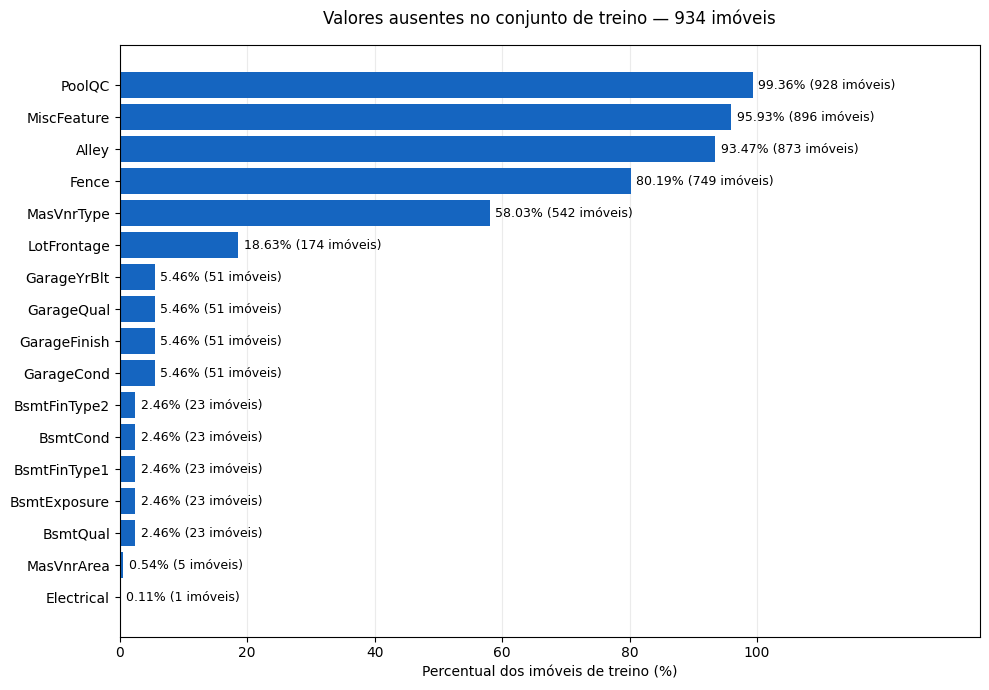

In [ ]:
import matplotlib.pyplot as plt

# Selecionar as colunas com valores ausentes no treino
dados_grafico = diagnostico_treino[
    diagnostico_treino["Quantidade ausente"] > 0
].sort_values("Percentual (%)", ascending=False)

fig, ax = plt.subplots(figsize=(10, 7))

barras = ax.barh(
    dados_grafico.index,
    dados_grafico["Percentual (%)"],
    color="#1565C0"
)

# Mostrar percentual e quantidade em cada barra
rotulos = [
    f"{percentual:.2f}% ({int(quantidade)} imóveis)"
    for percentual, quantidade in zip(
        dados_grafico["Percentual (%)"],
        dados_grafico["Quantidade ausente"]
    )
]

ax.bar_label(barras, labels=rotulos, padding=4, fontsize=9)

ax.invert_yaxis()
ax.set_xlim(0, 135)
ax.set_xticks(range(0, 101, 20))
ax.set_xlabel("Percentual dos imóveis de treino (%)")
ax.set_title(
    f"Valores ausentes no conjunto de treino — {len(X_treino)} imóveis",
    pad=15
)
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

## 16. Matriz de correlação de Pearson

**Objetivo.** Explorar associações lineares entre o preço e características numéricas do treino.

**Como os comandos funcionam.** `select_dtypes` seleciona números e `drop` remove `MSSubClass`. `corr(method="pearson")` calcula correlações com pares disponíveis. `abs().nlargest(10)` escolhe as dez maiores associações em magnitude com o preço; `sns.heatmap` mostra a submatriz com escala fixa entre −1 e 1.

**Leitura do resultado e cuidados.** A diagonal é 1 e a matriz é simétrica. A cor e o sinal do coeficiente indicam direção; a posição acima ou abaixo da diagonal não indica correlação positiva ou negativa. A seleção serve apenas ao gráfico, não reduz X. Correlação não estabelece causalidade, e pares podem ter diferentes quantidades de observações devido a ausências.

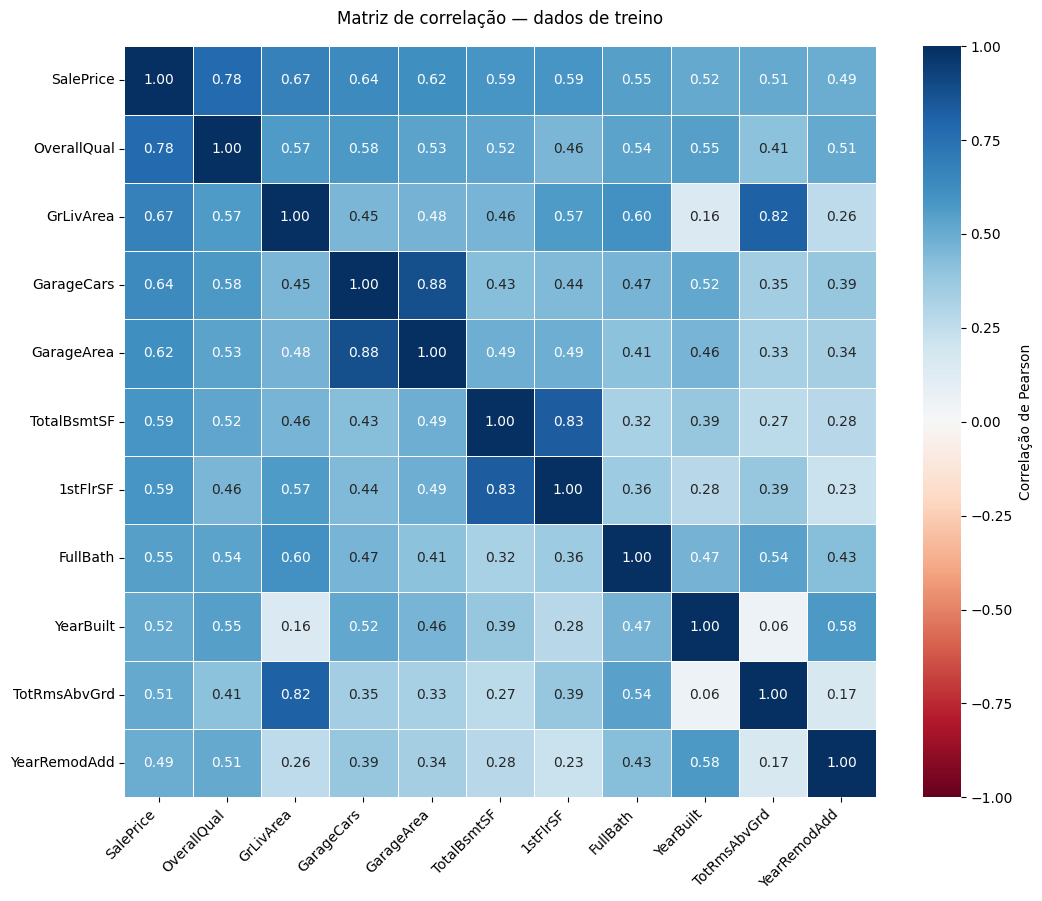

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Usar apenas os dados de treino
dados_correlacao = X_treino.select_dtypes(
    include="number"
).copy()

# Este campo contém códigos de categorias
dados_correlacao = dados_correlacao.drop(
    columns=["MSSubClass"], errors="ignore"
)

# Acrescentar o preço para analisar suas associações
dados_correlacao["SalePrice"] = y_treino

# Correlação de Pearson, usando os pares disponíveis
matriz = dados_correlacao.corr(method="pearson")

# Selecionar as 10 maiores associações com o preço
mais_correlacionadas = (
    matriz["SalePrice"]
    .drop("SalePrice")
    .dropna()
    .abs()
    .nlargest(10)
    .index.tolist()
)

selecionadas = ["SalePrice"] + mais_correlacionadas

# Desenhar a matriz completa e simétrica
plt.figure(figsize=(11, 9))

sns.heatmap(
    matriz.loc[selecionadas, selecionadas],
    annot=True,
    fmt=".2f",
    cmap="RdBu",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={"label": "Correlação de Pearson"}
)

plt.title("Matriz de correlação — dados de treino", pad=16)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## 17. Boxplots e violinos das distribuições

**Objetivo.** Examinar assimetria, dispersão e observações extremas no treino.

**Como os comandos funcionam.** A lista reúne preço, área habitável e área do terreno. `subplots(3, 2, sharey="row")` cria pares comparáveis. `dropna` remove ausências apenas da visualização. `sns.boxplot` resume quartis e extremos; `violinplot(inner="quartile", cut=0)` mostra densidade estimada e quartis.

**Leitura do resultado e cuidados.** O boxplot usa bigodes definidos pelo critério padrão de 1,5 intervalo interquartil. Pontos além deles não são automaticamente erros. O violino depende da suavização da densidade. Nenhum imóvel é excluído dos modelos nesta etapa; as áreas aparecem em pés quadrados.

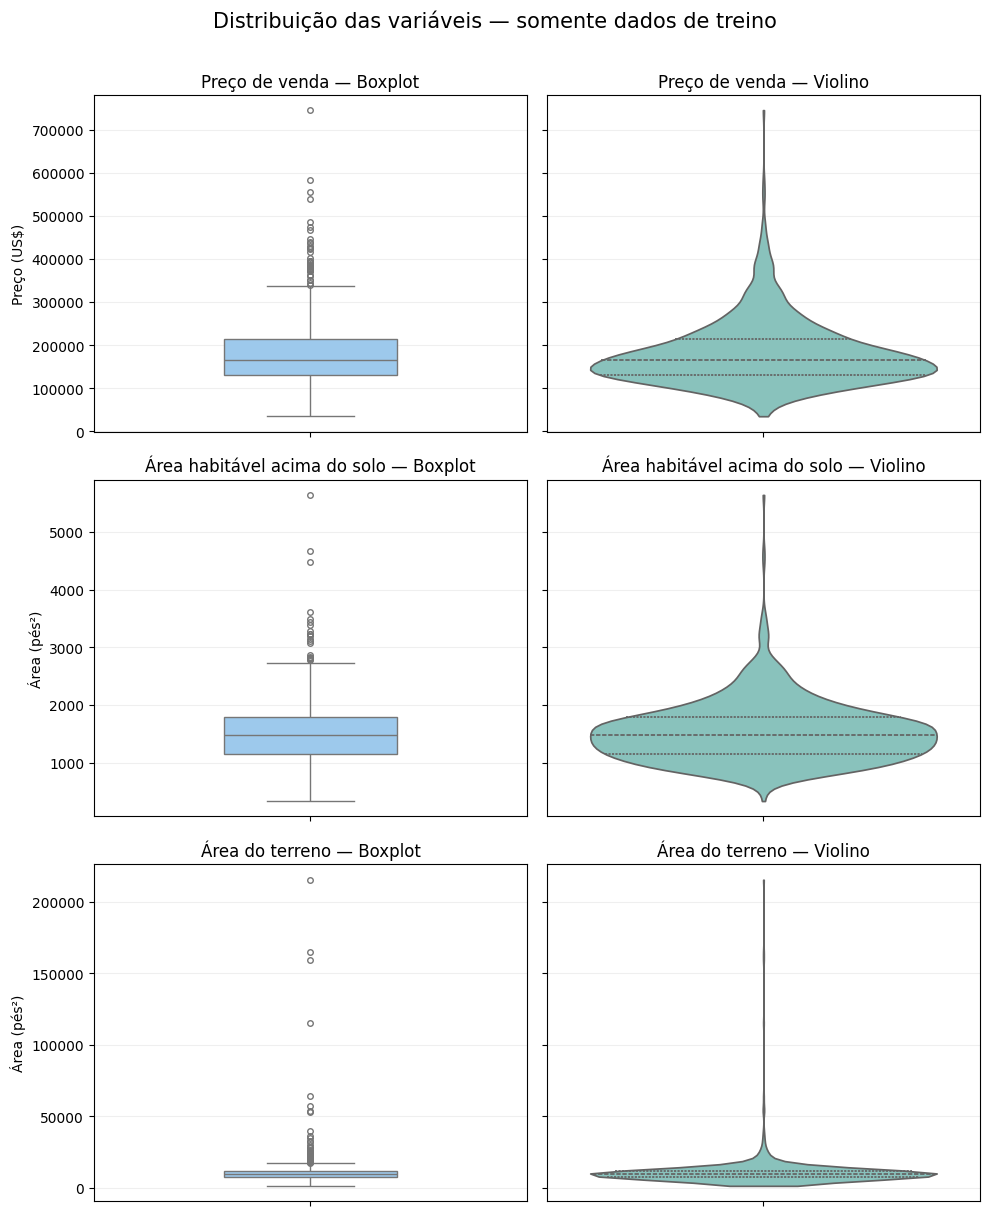

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

variaveis_graficos = [
    (y_treino, "Preço de venda", "Preço (US$)"),
    (X_treino["GrLivArea"], "Área habitável acima do solo", "Área (pés²)"),
    (X_treino["LotArea"], "Área do terreno", "Área (pés²)")
]

fig, eixos = plt.subplots(
    3, 2,
    figsize=(10, 12),
    sharey="row"
)

for linha, (valores, titulo, unidade) in enumerate(
    variaveis_graficos
):
    valores = valores.dropna()

    # Esquerda: resumo por mediana, quartis e bigodes
    sns.boxplot(
        y=valores,
        ax=eixos[linha, 0],
        color="#90CAF9",
        width=0.4,
        fliersize=4
    )

    # Direita: distribuição estimada e quartis internos
    sns.violinplot(
        y=valores,
        ax=eixos[linha, 1],
        color="#80CBC4",
        inner="quartile",
        cut=0
    )

    eixos[linha, 0].set_title(f"{titulo} — Boxplot")
    eixos[linha, 1].set_title(f"{titulo} — Violino")

    for eixo in eixos[linha]:
        eixo.set_ylabel(unidade)
        eixo.set_xlabel("")
        eixo.grid(axis="y", alpha=0.20)
        eixo.set_axisbelow(True)

fig.suptitle(
    "Distribuição das variáveis — somente dados de treino",
    fontsize=15,
    y=1.01
)

plt.tight_layout()
plt.show()

## 18. Correção do tipo de MSSubClass

**Objetivo.** Representar o tipo de residência como categoria, em vez de quantidade contínua.

**Como os comandos funcionam.** `astype(str)` converte seus códigos em texto nos três conjuntos. Em seguida, `select_dtypes` recalcula as listas de variáveis numéricas e categóricas.

**Leitura do resultado e cuidados.** Resultado: 35 numéricas e 44 categóricas, totalizando as mesmas 79 características. Evita-se impor uma distância numérica artificial entre códigos, por exemplo tratar 120 como o dobro de 60 no sentido de tipo residencial.

In [ ]:
# Converter o código do tipo de residência em categoria
for conjunto in [X_treino, X_validacao, X_teste]:
    conjunto["MSSubClass"] = conjunto["MSSubClass"].astype(str)

# Atualizar as listas de variáveis
colunas_numericas = X_treino.select_dtypes(
    include="number"
).columns.tolist()

colunas_categoricas = X_treino.select_dtypes(
    exclude="number"
).columns.tolist()

print("Colunas numéricas:", len(colunas_numericas))
print("Colunas categóricas:", len(colunas_categoricas))
print("Total de características:", X_treino.shape[1])

Colunas numéricas: 35
Colunas categóricas: 44
Total de características: 79


## 19. Regras para garagem e piscina

**Objetivo.** Completar categorias ausentes quando a inexistência do recurso está confirmada.

**Como os comandos funcionam.** `def tratar_ausencias_confirmadas` encapsula a regra em uma função que copia a entrada. `GarageCars.eq(0)` e `PoolArea.eq(0)` identificam ausência física; `isna()` restringe o preenchimento às categorias faltantes. A função é aplicada aos três conjuntos.

**Leitura do resultado e cuidados.** No treino, as quatro categorias de garagem indicam 51 imóveis sem garagem, e `PoolQC` indica 928 sem piscina. Não são quatro grupos distintos de 51 imóveis. O preenchimento usa informações da própria linha e não aprende estatísticas do teste.

In [ ]:
# Aplicar regras baseadas nas características de cada imóvel
def tratar_ausencias_confirmadas(dados):
    dados = dados.copy()

    # Garagem: preencher apenas categorias ausentes
    sem_garagem = dados["GarageCars"].eq(0)

    for coluna in [
        "GarageType", "GarageFinish", "GarageQual", "GarageCond"
    ]:
        mascara = sem_garagem & dados[coluna].isna()
        dados.loc[mascara, coluna] = "Sem garagem"

    # Piscina: confirmar a ausência pela área igual a zero
    sem_piscina = (
        dados["PoolArea"].eq(0)
        & dados["PoolQC"].isna()
    )
    dados.loc[sem_piscina, "PoolQC"] = "Sem piscina"

    return dados

# Aplicar as mesmas regras aos três conjuntos
X_treino = tratar_ausencias_confirmadas(X_treino)
X_validacao = tratar_ausencias_confirmadas(X_validacao)
X_teste = tratar_ausencias_confirmadas(X_teste)

# Conferir o resultado no treino
colunas_verificadas = [
    "GarageType", "GarageFinish",
    "GarageQual", "GarageCond", "PoolQC"
]

resumo_tratamento = pd.DataFrame({
    "Classificados como sem recurso": [
        X_treino[coluna].isin(
            ["Sem garagem", "Sem piscina"]
        ).sum()
        for coluna in colunas_verificadas
    ],
    "Ausências restantes": [
        X_treino[coluna].isna().sum()
        for coluna in colunas_verificadas
    ]
}, index=colunas_verificadas)

display(resumo_tratamento)

,Classificados como sem recurso,Ausências restantes
GarageType,51,0
GarageFinish,51,0
GarageQual,51,0
GarageCond,51,0
PoolQC,928,0


## 20. Regras para ausência de porão

**Objetivo.** Distinguir inexistência de porão de informação desconhecida sobre um porão existente.

**Como os comandos funcionam.** `TotalBsmtSF.eq(0)` identifica área de porão zero. O laço percorre cinco características de porão e usa `loc` para preencher apenas NaNs nessas linhas com `Sem porão`. Uma tabela confere a contagem e as ausências restantes.

**Leitura do resultado e cuidados.** No treino, 23 imóveis foram classificados como sem porão em cada uma das cinco colunas e não restaram ausências nessas colunas. Se houvesse área positiva e categoria ausente, essa informação não seria classificada como inexistência do recurso.

In [ ]:
colunas_porao = [
    "BsmtQual", "BsmtCond", "BsmtExposure",
    "BsmtFinType1", "BsmtFinType2"
]

# Aplicar a mesma regra aos três conjuntos
for conjunto in [X_treino, X_validacao, X_teste]:
    sem_porao = conjunto["TotalBsmtSF"].eq(0)

    for coluna in colunas_porao:
        mascara = sem_porao & conjunto[coluna].isna()
        conjunto.loc[mascara, coluna] = "Sem porão"

# Conferir o resultado no treino
resumo_porao = pd.DataFrame({
    "Classificados como sem porão": [
        X_treino[coluna].eq("Sem porão").sum()
        for coluna in colunas_porao
    ],
    "Ausências restantes": [
        X_treino[coluna].isna().sum()
        for coluna in colunas_porao
    ]
}, index=colunas_porao)

display(resumo_porao)

,Classificados como sem porão,Ausências restantes
BsmtQual,23,0
BsmtCond,23,0
BsmtExposure,23,0
BsmtFinType1,23,0
BsmtFinType2,23,0


## 21. Imputação numérica e indicadores de ausência

**Objetivo.** Preencher valores numéricos desconhecidos sem aprender parâmetros na validação ou no teste.

**Como os comandos funcionam.** `median()` calcula as medianas somente no treino. `isna().any()` identifica quais colunas necessitam de indicadores. A função `preparar_numericas` cria campos terminados em `_ausente` com 0 ou 1 e aplica `fillna(medianas_treino)` a todos os conjuntos.

**Leitura do resultado e cuidados.** Medianas registradas: `LotFrontage` 70, `MasVnrArea` 0 e `GarageYrBlt` 1979. Há três indicadores adicionais, elevando o total preparado a 82 colunas. O ano imputado de garagem não é o ano real do imóvel sem garagem; o indicador e a categoria preservam essa distinção. Em futura validação cruzada, as medianas e a escolha de indicadores devem ser recalculadas dentro de cada dobra.

In [ ]:
# Calcular medianas somente com os dados de treino
medianas_treino = X_treino[colunas_numericas].median()

# Identificar colunas numéricas com ausências no treino
numericas_com_ausencias = [
    coluna for coluna in colunas_numericas
    if X_treino[coluna].isna().any()
]

# Registrar o diagnóstico antes do preenchimento
resumo_imputacao = pd.DataFrame({
    "Ausentes no treino": (
        X_treino[numericas_com_ausencias].isna().sum()
    ),
    "Mediana usada": medianas_treino[numericas_com_ausencias]
})

def preparar_numericas(dados):
    dados = dados.copy()

    # 1 indica que o valor original estava ausente
    for coluna in numericas_com_ausencias:
        dados[coluna + "_ausente"] = (
            dados[coluna].isna().astype(int)
        )

    # Preencher usando sempre as medianas do treino
    dados[colunas_numericas] = (
        dados[colunas_numericas].fillna(medianas_treino)
    )

    return dados

# Criar versões preparadas, preservando as anteriores
X_treino_preparado = preparar_numericas(X_treino)
X_validacao_preparado = preparar_numericas(X_validacao)
X_teste_preparado = preparar_numericas(X_teste)

display(resumo_imputacao)

print("\nAusências numéricas restantes:")
for nome, dados in [
    ("Treino", X_treino_preparado),
    ("Validação", X_validacao_preparado),
    ("Teste", X_teste_preparado)
]:
    print(nome, ":", dados[colunas_numericas].isna().sum().sum())

,Ausentes no treino,Mediana usada
LotFrontage,174,70.0
MasVnrArea,5,0.0
GarageYrBlt,51,1979.0



Ausências numéricas restantes:
Treino : 0
Validação : 0
Teste : 0


## 22. Tratamento das categorias restantes

**Objetivo.** Completar categorias com rótulos que conservem o significado das ausências.

**Como os comandos funcionam.** O dicionário `categorias_sem_recurso` associa `Alley`, `Fence` e `MiscFeature` a rótulos explícitos. `fillna` aplica essas regras. Nas demais categorias, `fillna("Não informado")` preserva a falta de informação como categoria própria.

**Leitura do resultado e cuidados.** A conferência registrou zero ausências nos três conjuntos preparados. Zero NaNs não significa dados perfeitos: a imputação introduz representações e hipóteses. O caso particular de `MasVnrType` é revisto na célula seguinte para recuperar textos que a leitura inicial interpretou como NaN.

In [ ]:
# Ausências que representam inexistência do recurso no dicionário
categorias_sem_recurso = {
    "Alley": "Sem acesso por viela",
    "Fence": "Sem cerca",
    "MiscFeature": "Sem recurso adicional"
}

for conjunto in [
    X_treino_preparado,
    X_validacao_preparado,
    X_teste_preparado
]:
    for coluna, significado in categorias_sem_recurso.items():
        conjunto[coluna] = conjunto[coluna].fillna(significado)

    # Preservar as demais ausências como categoria própria
    conjunto[colunas_categoricas] = (
        conjunto[colunas_categoricas].fillna("Não informado")
    )

# Conferir todas as colunas
print("Total de valores ausentes após o tratamento:")

for nome, conjunto in [
    ("Treino", X_treino_preparado),
    ("Validação", X_validacao_preparado),
    ("Teste", X_teste_preparado)
]:
    print(f"{nome}: {conjunto.isna().sum().sum()}")

Total de valores ausentes após o tratamento:
Treino: 0
Validação: 0
Teste: 0


## 23. Recuperação do significado de MasVnrType

**Objetivo.** Separar ausência de revestimento de ausência de informação.

**Como os comandos funcionam.** `read_csv(usecols=["MasVnrType"], keep_default_na=False)` relê apenas essa coluna preservando os textos. `str.strip` remove espaços; `replace` traduz `None` para ausência do recurso e valores vazios/NA para desconhecimento. `loc[conjunto.index]` alinha os dados às linhas de cada amostra.

**Leitura do resultado e cuidados.** No treino foram registrados 537 imóveis sem revestimento de alvenaria, 293 `BrkFace`, 89 `Stone`, 10 `BrkCmn` e 5 não informados. Essa recuperação usa a representação original do próprio campo, não estatísticas nem preços do teste.

In [ ]:
# Ler esta coluna preservando os textos originais do CSV
tipo_revestimento = pd.read_csv(
    pasta / "train.csv",
    usecols=["MasVnrType"],
    keep_default_na=False
)["MasVnrType"].str.strip()

# Interpretar os textos sem confundir ausência de recurso
# com ausência de informação
tipo_revestimento = tipo_revestimento.replace({
    "None": "Sem revestimento de alvenaria",
    "": "Não informado",
    "NA": "Não informado",
    "NaN": "Não informado"
})

# Recuperar os valores nas mesmas linhas de cada conjunto
for conjunto in [
    X_treino_preparado,
    X_validacao_preparado,
    X_teste_preparado
]:
    conjunto["MasVnrType"] = tipo_revestimento.loc[
        conjunto.index
    ]

print("Tipos de revestimento no treino:")
display(
    X_treino_preparado["MasVnrType"]
    .value_counts(dropna=False)
    .rename("Quantidade de imóveis")
    .to_frame()
)

Tipos de revestimento no treino:


,Quantidade de imóveis
MasVnrType,
Sem revestimento de alvenaria,537
BrkFace,293
Stone,89
BrkCmn,10
Não informado,5


## 24. Padronização e codificação das entradas

**Objetivo.** Gerar uma matriz numérica compatível com as redes e com o Elastic Net.

**Como os comandos funcionam.** `ColumnTransformer` aplica `StandardScaler` às numéricas, incluindo indicadores, e `OneHotEncoder` às categorias. `fit_transform` aprende médias, escalas e categorias somente no treino; `transform` reaplica o mesmo objeto aos demais conjuntos. `handle_unknown="ignore"` aceita categorias novas e `sparse_output=False` produz matriz densa. `astype("float32")` reduz o tamanho dos números.

**Leitura do resultado e cuidados.** Foram produzidas matrizes (934, 316), (234, 316) e (292, 316), todas finitas. Categorias desconhecidas ficam com zeros no bloco correspondente. Os indicadores numéricos também são padronizados; as colunas one-hot não são padronizadas por esse transformador. O CatBoost utilizará os DataFrames preparados, antes desta codificação.

In [ ]:
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Identificar as colunas, incluindo os indicadores adicionados
numericas_modelo = X_treino_preparado.select_dtypes(
    include="number"
).columns.tolist()

categoricas_modelo = X_treino_preparado.select_dtypes(
    exclude="number"
).columns.tolist()

# Definir os tratamentos
preprocessador = ColumnTransformer([
    ("numericas", StandardScaler(), numericas_modelo),
    ("categoricas", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ), categoricas_modelo)
])

# Aprender escalas e categorias somente no treino
X_treino_modelo = preprocessador.fit_transform(
    X_treino_preparado
).astype("float32")

# Aplicar o mesmo tratamento à validação e ao teste
X_validacao_modelo = preprocessador.transform(
    X_validacao_preparado
).astype("float32")

X_teste_modelo = preprocessador.transform(
    X_teste_preparado
).astype("float32")

# Conferir dimensões e validade dos números
for nome, dados in [
    ("Treino", X_treino_modelo),
    ("Validação", X_validacao_modelo),
    ("Teste", X_teste_modelo)
]:
    print(
        f"{nome}: {dados.shape} | "
        f"Todos os números válidos: {np.isfinite(dados).all()}"
    )

Treino: (934, 316) | Todos os números válidos: True
Validação: (234, 316) | Todos os números válidos: True
Teste: (292, 316) | Todos os números válidos: True


## 25. Desenho da arquitetura de referência

**Objetivo.** Explicar visualmente as entradas, camadas ocultas, saída, pesos e bias.

**Como os comandos funcionam.** `tamanhos` define 316 → 128 → 64 → 1. Os laços calculam coordenadas dos pontos; `scatter` desenha todos os nós e `plot` mostra uma amostra das conexões. A expressão `(entradas + 1) * saidas` soma os pesos e um bias por neurônio de cada camada densa.

**Leitura do resultado e cuidados.** A rede tem duas camadas ocultas, não 128 camadas. Os blocos de pontos são uma organização visual de uma camada. São 40.576 + 8.256 + 65 = 48.897 parâmetros treináveis. Os 316 valores de entrada são características transformadas, não 316 características originais. Esta célula desenha, mas não cria nem treina o modelo Keras.

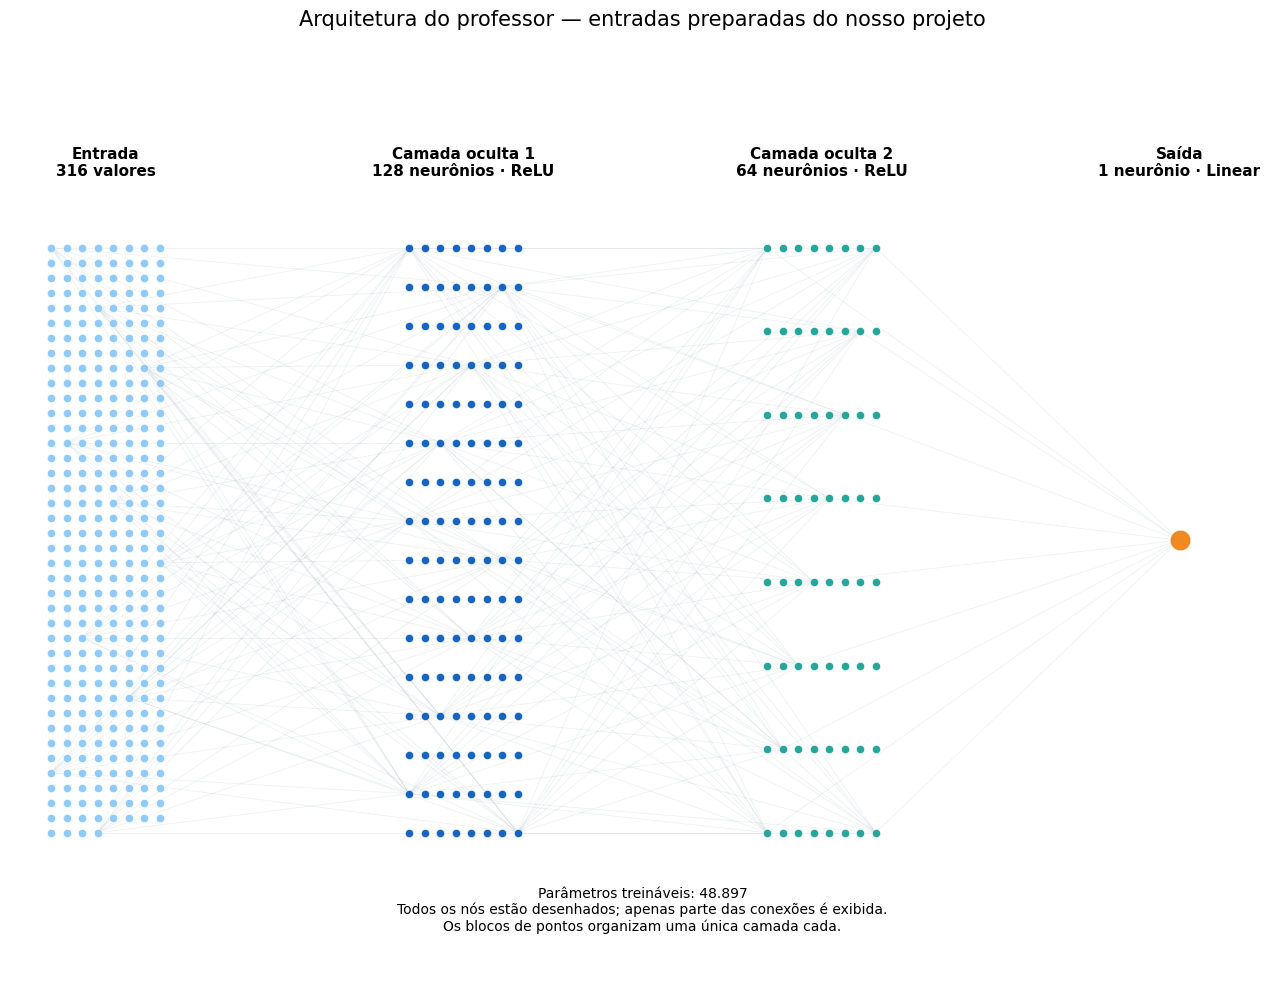

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Arquitetura do professor com nossas entradas preparadas
tamanhos = [X_treino_modelo.shape[1], 128, 64, 1]
titulos = [
    f"Entrada\n{tamanhos[0]} valores",
    "Camada oculta 1\n128 neurônios · ReLU",
    "Camada oculta 2\n64 neurônios · ReLU",
    "Saída\n1 neurônio · Linear"
]
cores = ["#90CAF9", "#1565C0", "#26A69A", "#EF8A23"]

fig, ax = plt.subplots(figsize=(13, 10))
posicoes = []

# Distribuir todos os nós em pequenos blocos
for etapa, quantidade in enumerate(tamanhos):
    colunas = 8 if quantidade > 1 else 1
    linhas = int(np.ceil(quantidade / colunas))

    pontos = []
    for numero in range(quantidade):
        coluna = numero % colunas
        linha = numero // colunas

        x = etapa * 3 + (
            (coluna - (colunas - 1) / 2) * 0.13
        )
        y = (
            0.5 if linhas == 1
            else 0.92 - linha * 0.84 / (linhas - 1)
        )
        pontos.append((x, y))

    posicoes.append(np.array(pontos))

# Mostrar uma amostra das conexões entre camadas
for etapa in range(3):
    origem = posicoes[etapa]
    destino = posicoes[etapa + 1]

    indices_origem = np.linspace(
        0, len(origem) - 1, min(10, len(origem)), dtype=int
    )
    indices_destino = np.linspace(
        0, len(destino) - 1, min(10, len(destino)), dtype=int
    )

    for i in indices_origem:
        for j in indices_destino:
            ax.plot(
                [origem[i, 0], destino[j, 0]],
                [origem[i, 1], destino[j, 1]],
                color="#78909C",
                alpha=0.12,
                linewidth=0.6,
                zorder=1
            )

# Desenhar todos os nós
for etapa, pontos in enumerate(posicoes):
    ax.scatter(
        pontos[:, 0], pontos[:, 1],
        s=35 if etapa < 3 else 220,
        color=cores[etapa],
        edgecolor="white",
        linewidth=0.4,
        zorder=2
    )
    ax.text(
        etapa * 3, 1.02, titulos[etapa],
        ha="center", va="bottom", fontsize=11,
        fontweight="bold"
    )

# Cada camada densa aprende pesos e um bias por neurônio
parametros = sum(
    (tamanhos[i] + 1) * tamanhos[i + 1]
    for i in range(3)
)

ax.set_title(
    "Arquitetura do professor — entradas preparadas do nosso projeto",
    fontsize=15, pad=45
)
ax.text(
    4.5, -0.06,
    f"Parâmetros treináveis: {parametros:,}".replace(",", ".")
    + "\nTodos os nós estão desenhados; apenas parte das conexões é exibida."
    + "\nOs blocos de pontos organizam uma única camada cada.",
    ha="center", fontsize=10
)

ax.set_xlim(-0.8, 9.8)
ax.set_ylim(-0.13, 1.15)
ax.axis("off")
plt.tight_layout()
plt.show()

## 26. Treinamento e validação da rede de referência

**Objetivo.** Estabelecer uma comparação baseada na arquitetura inicial do professor sob o protocolo corrigido.

**Como os comandos funcionam.** `set_random_seed(42)` fixa sementes. `Sequential` organiza camadas `Dense`: 128 e 64 com ReLU e saída linear. `compile` define Adam com taxa 0,005, perda MSE e métrica MAE. `fit` treina 100 épocas em lotes de 32, acompanhando a validação. `predict().ravel()` gera um vetor e as funções de métricas avaliam os preços.

**Leitura do resultado e cuidados.** Na validação final: MAE 19.241,29, RMSE 29.868,88 e R² 0,8620. O modelo mantido corresponde à época 100, sem restauração da melhor época. A referência compartilha nossa preparação e nossas amostras com as alternativas; não reproduz integralmente o código original do professor. Sementes ajudam, mas não asseguram igualdade bit a bit entre ambientes.

In [ ]:
import tensorflow as tf
from tensorflow import keras
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score
)

# Fixar a semente para facilitar a reprodução
keras.utils.set_random_seed(42)

# Rede com a arquitetura inicial do professor
modelo_referencia = keras.Sequential([
    keras.Input(shape=(X_treino_modelo.shape[1],)),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dense(1)
])

modelo_referencia.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.005),
    loss="mse",
    metrics=["mae"]
)

# Treinar e acompanhar a validação
historico_referencia = modelo_referencia.fit(
    X_treino_modelo,
    y_treino.to_numpy(dtype="float32"),
    validation_data=(
        X_validacao_modelo,
        y_validacao.to_numpy(dtype="float32")
    ),
    epochs=100,
    batch_size=32,
    verbose=2
)

# Avaliar somente na validação nesta etapa
previsao_referencia_val = modelo_referencia.predict(
    X_validacao_modelo, verbose=0
).ravel()

mse_referencia = mean_squared_error(
    y_validacao, previsao_referencia_val
)

resultado_referencia = {
    "Modelo": "Rede de referência",
    "MAE": mean_absolute_error(
        y_validacao, previsao_referencia_val
    ),
    "MSE": mse_referencia,
    "RMSE": np.sqrt(mse_referencia),
    "R²": r2_score(y_validacao, previsao_referencia_val)
}

print("\nRESULTADO NA VALIDAÇÃO:")
display(pd.DataFrame([resultado_referencia]).round(2))

Epoch 1/100
30/30 - 1s - 47ms/step - loss: 38530703360.0000 - mae: 180827.4531 - val_loss: 39612932096.0000 - val_mae: 182130.5938
Epoch 2/100
30/30 - 0s - 5ms/step - loss: 37098655744.0000 - mae: 177114.2344 - val_loss: 36138557440.0000 - val_mae: 172994.2812
Epoch 3/100
30/30 - 0s - 10ms/step - loss: 30191503360.0000 - mae: 157768.2812 - val_loss: 24445759488.0000 - val_mae: 138153.3438
Epoch 4/100
30/30 - 0s - 6ms/step - loss: 15418609664.0000 - mae: 105000.8203 - val_loss: 7833808896.0000 - val_mae: 65442.8945
Epoch 5/100
30/30 - 0s - 6ms/step - loss: 3719710720.0000 - mae: 39072.9297 - val_loss: 2305676544.0000 - val_mae: 33116.8945
Epoch 6/100
30/30 - 0s - 5ms/step - loss: 2045700480.0000 - mae: 30646.3516 - val_loss: 1793972352.0000 - val_mae: 28892.7520
Epoch 7/100
30/30 - 0s - 5ms/step - loss: 1724664960.0000 - mae: 25874.3125 - val_loss: 1535570688.0000 - val_mae: 25860.6094
Epoch 8/100
30/30 - 0s - 10ms/step - loss: 1554418816.0000 - mae: 24139.8359 - val_loss: 1385623296.00

,Modelo,MAE,MSE,RMSE,R²
0,Rede de referência,19241.29,892149952.0,29868.88,0.86


## 27. Curvas de aprendizagem da referência

**Objetivo.** Comparar a evolução dos erros de treino e validação durante as épocas.

**Como os comandos funcionam.** `historico_referencia.history` contém as métricas registradas. `arange` constrói o eixo de épocas. `argmin(val_loss) + 1` encontra a melhor época pelo MSE. `sqrt(loss)` produz RMSE, pois a referência usa MSE sem regularização. `axvline` marca o mínimo da validação nos dois painéis.

**Leitura do resultado e cuidados.** O mínimo de MSE de validação ocorre na época 45. A linha pontilhada no painel MAE continua marcando o mínimo de MSE, não necessariamente o de MAE. Métricas de treino são acumuladas durante atualizações dos pesos; a validação é calculada ao fim da época. A separação posterior das curvas é compatível com sobreajuste nesta execução.

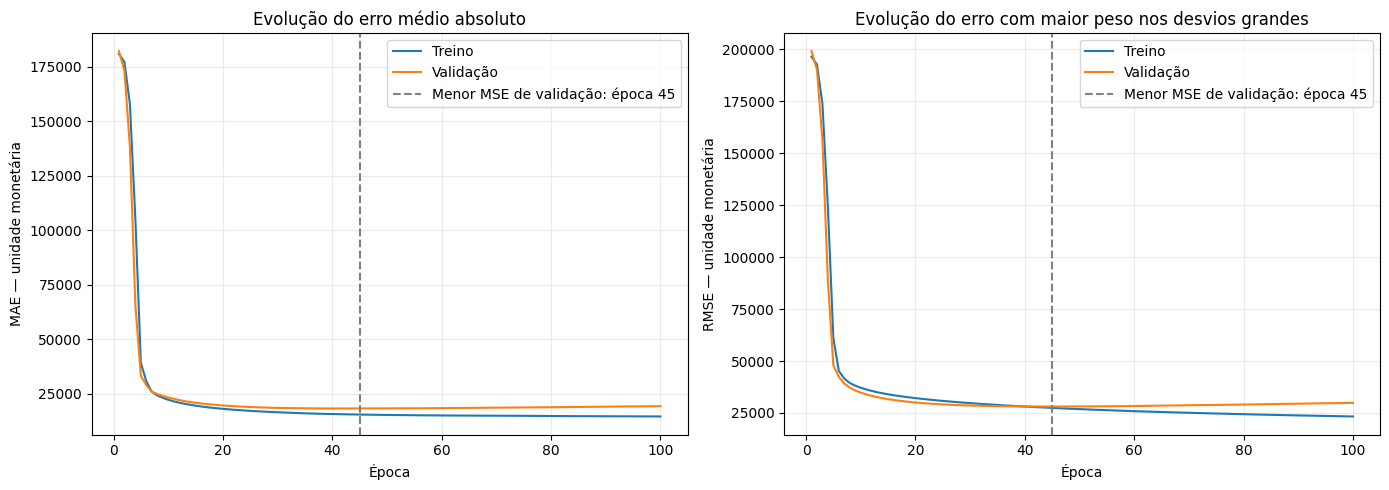

Época com menor MSE de validação: 45
A tabela anterior corresponde ao modelo ao final da época 100.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

historico = historico_referencia.history
epocas = np.arange(1, len(historico["loss"]) + 1)

melhor_epoca = int(np.argmin(historico["val_loss"])) + 1

fig, eixos = plt.subplots(1, 2, figsize=(14, 5))

eixos[0].plot(epocas, historico["mae"], label="Treino")
eixos[0].plot(epocas, historico["val_mae"], label="Validação")
eixos[0].set_title("Evolução do erro médio absoluto")
eixos[0].set_ylabel("MAE — unidade monetária")

eixos[1].plot(
    epocas, np.sqrt(historico["loss"]), label="Treino"
)
eixos[1].plot(
    epocas, np.sqrt(historico["val_loss"]), label="Validação"
)
eixos[1].set_title("Evolução do erro com maior peso nos desvios grandes")
eixos[1].set_ylabel("RMSE — unidade monetária")

for eixo in eixos:
    eixo.axvline(
        melhor_epoca,
        color="gray",
        linestyle="--",
        label=f"Menor MSE de validação: época {melhor_epoca}"
    )
    eixo.set_xlabel("Época")
    eixo.grid(alpha=0.25)
    eixo.legend()

plt.tight_layout()
plt.show()

print(f"Época com menor MSE de validação: {melhor_epoca}")
print("A tabela anterior corresponde ao modelo ao final da época 100.")

## 28. Quantificação da piora após a melhor época

**Objetivo.** Mensurar a diferença entre os melhores resultados registrados e o final do treinamento.

**Como os comandos funcionam.** `argmin` localiza separadamente mínimos de `val_loss` e `val_mae`. Uma compreensão de lista cria as três linhas da tabela. A razão entre RMSE final e mínimo, menos 1 e multiplicada por 100, calcula a piora relativa.

**Leitura do resultado e cuidados.** Época 45: MAE 18.197,89 e RMSE 28.112,88. Época 41: menor MAE, 18.175,50. Época 100: RMSE 29.868,88, 6,25% acima do mínimo. O histórico armazena essas métricas, não os pesos daquela época; essa célula não recupera o modelo da época 45.

In [ ]:
h = historico_referencia.history

epoca_mse = int(np.argmin(h["val_loss"]))
epoca_mae = int(np.argmin(h["val_mae"]))
ultima = len(h["loss"]) - 1

comparacao_epocas = pd.DataFrame([
    {
        "Momento": nome,
        "Época": i + 1,
        "MAE de validação": h["val_mae"][i],
        "RMSE de validação": np.sqrt(h["val_loss"][i])
    }
    for nome, i in [
        ("Menor MSE de validação", epoca_mse),
        ("Menor MAE de validação", epoca_mae),
        ("Final do treinamento", ultima)
    ]
])

display(comparacao_epocas.round(2))

aumento_rmse = (
    np.sqrt(h["val_loss"][ultima] / h["val_loss"][epoca_mse]) - 1
) * 100

print(f"Aumento do RMSE entre a melhor época e a última: {aumento_rmse:.2f}%")

,Momento,Época,MAE de validação,RMSE de validação
0,Menor MSE de validação,45,18197.89,28112.88
1,Menor MAE de validação,41,18175.50,28132.72
2,Final do treinamento,100,19241.29,29868.88


Aumento do RMSE entre a melhor época e a última: 6.25%


### Diagnóstico da Rede de Referência

O menor RMSE de validação ocorreu na época 45: 28.112,88. O menor MAE ocorreu na época 41: 18.175,50.

Ao final das 100 épocas, o RMSE aumentou para 29.868,88, uma piora de 6,25% em relação ao melhor resultado.

As curvas mostram redução do erro de treinamento acompanhada de piora na validação, um padrão compatível com sobreajuste nesta execução.

Esse diagnóstico fundamenta o uso de EarlyStopping com restauração dos melhores pesos na próxima proposta.

A conclusão se limita à execução e à divisão de dados analisadas. O conjunto de teste permanece reservado para a avaliação final.

## 29. Alternativa 1 — MLP regularizada com preço em log

**Objetivo.** Testar uma rede menor com regularização e seleção da melhor época.

**Como os comandos funcionam.** `log1p` transforma o preço em ln(1 + preço); `reshape(-1, 1)` ajusta a forma para o scaler. `escala_preco.fit_transform` padroniza o alvo usando apenas treino. A rede 64/32 usa penalidade L2 de 0,001 e Adam 0,001. `EarlyStopping(monitor="val_mse", patience=30, restore_best_weights=True)` monitora MSE sem a penalidade L2 na escala transformada. `inverse_transform` e `expm1` devolvem a previsão à escala de preço.

**Leitura do resultado e cuidados.** A execução parou na época 83 e restaurou a 53. São 22.401 parâmetros, 54,19% menos que a referência. A validação produziu MAE 15.201,91 e RMSE 25.739,27. A transformação muda o critério de ajuste: minimizar erro em log não equivale a minimizar MSE monetário. A inversão não inclui correção de retransformação para estimar a média condicional. Como várias mudanças foram combinadas, o ganho não pode ser atribuído isoladamente a uma delas.

In [ ]:
# ALTERNATIVA 1 — REDE NEURAL REGULARIZADA
import numpy as np
import pandas as pd
from tensorflow import keras
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score
)

keras.utils.set_random_seed(42)

# 1. Transformar o preço.
# A média e o desvio são calculados apenas no treino.
escala_preco = StandardScaler()

y_treino_log = np.log1p(
    y_treino.to_numpy(dtype="float64")
).reshape(-1, 1)

y_validacao_log = np.log1p(
    y_validacao.to_numpy(dtype="float64")
).reshape(-1, 1)

y_treino_rede = escala_preco.fit_transform(
    y_treino_log
).astype("float32")

y_validacao_rede = escala_preco.transform(
    y_validacao_log
).astype("float32")

# 2. Construir uma rede menor, com regularização.
modelo_mlp = keras.Sequential([
    keras.Input(shape=(X_treino_modelo.shape[1],)),
    keras.layers.Dense(
        64, activation="relu",
        kernel_regularizer=keras.regularizers.l2(0.001)
    ),
    keras.layers.Dense(
        32, activation="relu",
        kernel_regularizer=keras.regularizers.l2(0.001)
    ),
    keras.layers.Dense(1)
])

modelo_mlp.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=[keras.metrics.MeanSquaredError(name="mse")]
)

# 3. Monitorar o erro de validação sem a penalidade L2.
parada_mlp = keras.callbacks.EarlyStopping(
    monitor="val_mse",
    mode="min",
    patience=30,
    restore_best_weights=True,
    verbose=1
)

# 4. Treinar: 500 é o limite, não uma obrigação.
historico_mlp = modelo_mlp.fit(
    X_treino_modelo,
    y_treino_rede,
    validation_data=(X_validacao_modelo, y_validacao_rede),
    epochs=500,
    batch_size=32,
    callbacks=[parada_mlp],
    verbose=0
)

# 5. Retornar as previsões à unidade original do preço.
previsao_padronizada = modelo_mlp.predict(
    X_validacao_modelo, verbose=0
)

previsao_log = escala_preco.inverse_transform(
    previsao_padronizada
).ravel()

previsao_mlp_val = np.expm1(previsao_log)

# 6. Comparar usando as mesmas métricas e a mesma validação.
mse_mlp = mean_squared_error(y_validacao, previsao_mlp_val)

resultado_mlp = {
    "Modelo": "MLP regularizada — preço em log",
    "MAE": mean_absolute_error(y_validacao, previsao_mlp_val),
    "MSE": mse_mlp,
    "RMSE": np.sqrt(mse_mlp),
    "R²": r2_score(y_validacao, previsao_mlp_val)
}

print("Épocas executadas:", len(historico_mlp.history["loss"]))
print(
    "Melhor época pelo MSE na escala log padronizada:",
    int(np.argmin(historico_mlp.history["val_mse"])) + 1
)
print("Parâmetros da nova rede:", modelo_mlp.count_params())

display(
    pd.DataFrame([resultado_referencia, resultado_mlp]).round(2)
)

Epoch 83: early stopping
Restoring model weights from the end of the best epoch: 53.
Épocas executadas: 83
Melhor época pelo MSE na escala log padronizada: 53
Parâmetros da nova rede: 22401


,Modelo,MAE,MSE,RMSE,R²
0,Rede de referência,19241.29,892149952.0,29868.88,0.86
1,MLP regularizada — preço em log,15201.91,662510016.0,25739.27,0.90


## 30. Alternativa 2 — Elastic Net e seleção da regularização

**Objetivo.** Avaliar uma regressão linear regularizada para o logaritmo do preço.

**Como os comandos funcionam.** `ElasticNet` combina L1 e L2; `alpha` controla a força total e `l1_ratio` sua composição. Dois laços testam quatro valores de alpha e três proporções, totalizando 12 modelos. Cada candidato é ajustado apenas no treino; `expm1` reverte o log. O menor RMSE monetário de validação determina o modelo conservado.

**Leitura do resultado e cuidados.** Configuração selecionada: alpha 0,0001 e l1_ratio 0,8; 219 dos 316 coeficientes são diferentes de zero. A contagem corresponde às entradas transformadas, não a 219 variáveis originais. Não foi feita validação cruzada nesta busca. Validação: MAE 15.526,66 e RMSE 23.664,07. A seleção pelo próprio conjunto de validação torna sua avaliação preliminar; o teste é a etapa final.

In [ ]:
# ALTERNATIVA 2 — ELASTIC NET COM PREÇO EM LOG
import numpy as np
import pandas as pd
from sklearn.linear_model import ElasticNet
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score
)

# Reutilizar as entradas já preparadas com ajuste apenas no treino.
X_treino_elastic = X_treino_modelo.astype("float64")
X_validacao_elastic = X_validacao_modelo.astype("float64")

# O modelo aprenderá o logaritmo do preço.
y_treino_elastic = np.log1p(
    y_treino.to_numpy(dtype="float64")
)

# Quatro intensidades e três combinações de L1/L2.
valores_alpha = [0.0001, 0.001, 0.01, 0.1]
valores_l1 = [0.2, 0.5, 0.8]

experimentos_elastic = []
melhor_rmse_elastic = np.inf

for alpha in valores_alpha:
    for proporcao_l1 in valores_l1:

        candidato = ElasticNet(
            alpha=alpha,
            l1_ratio=proporcao_l1,
            max_iter=50000,
            tol=0.00001
        )

        candidato.fit(X_treino_elastic, y_treino_elastic)

        # Retornar à unidade original do preço.
        previsao = np.expm1(
            candidato.predict(X_validacao_elastic)
        )

        mse = mean_squared_error(y_validacao, previsao)
        rmse = np.sqrt(mse)

        experimentos_elastic.append({
            "alpha": alpha,
            "l1_ratio": proporcao_l1,
            "MAE": mean_absolute_error(y_validacao, previsao),
            "RMSE": rmse,
            "R²": r2_score(y_validacao, previsao)
        })

        # Guardar o melhor modelo e suas previsões.
        if rmse < melhor_rmse_elastic:
            melhor_rmse_elastic = rmse
            modelo_elastic = candidato
            previsao_elastic_val = previsao.copy()

# Registrar o resultado selecionado.
resultado_elastic = {
    "Modelo": "Elastic Net — preço em log",
    "MAE": mean_absolute_error(
        y_validacao, previsao_elastic_val
    ),
    "MSE": mean_squared_error(
        y_validacao, previsao_elastic_val
    ),
    "RMSE": melhor_rmse_elastic,
    "R²": r2_score(y_validacao, previsao_elastic_val)
}

tabela_busca_elastic = pd.DataFrame(
    experimentos_elastic
).sort_values("RMSE").reset_index(drop=True)

print("CONFIGURAÇÃO SELECIONADA")
print("alpha:", modelo_elastic.alpha)
print("l1_ratio:", modelo_elastic.l1_ratio)
print(
    "Coeficientes diferentes de zero:",
    np.count_nonzero(modelo_elastic.coef_),
    "de", X_treino_elastic.shape[1]
)

print("\nCINCO MELHORES CONFIGURAÇÕES NA VALIDAÇÃO")
display(tabela_busca_elastic.head().round(4))

print("\nCOMPARAÇÃO DOS MODELOS NA VALIDAÇÃO")
display(
    pd.DataFrame([
        resultado_referencia,
        resultado_mlp,
        resultado_elastic
    ]).round(2)
)

CONFIGURAÇÃO SELECIONADA
alpha: 0.0001
l1_ratio: 0.8
Coeficientes diferentes de zero: 219 de 316

CINCO MELHORES CONFIGURAÇÕES NA VALIDAÇÃO


,alpha,l1_ratio,MAE,RMSE,R²
0,0.0001,0.8,15526.6561,23664.0675,0.9134
1,0.0010,0.8,15445.5824,24008.2918,0.9108
2,0.0001,0.5,15789.1660,24120.1165,0.9100
3,0.0010,0.5,15574.7791,24319.0456,0.9085
4,0.0001,0.2,16168.3569,24772.1084,0.9051



COMPARAÇÃO DOS MODELOS NA VALIDAÇÃO


,Modelo,MAE,MSE,RMSE,R²
0,Rede de referência,19241.29,8.921500e+08,29868.88,0.86
1,MLP regularizada — preço em log,15201.91,6.625100e+08,25739.27,0.90
2,Elastic Net — preço em log,15526.66,5.599881e+08,23664.07,0.91


## 31. Alternativa 3 — CatBoost com categorias preservadas

**Objetivo.** Testar boosting de árvores com tratamento interno das variáveis categóricas.

**Como os comandos funcionam.** `%pip install` instala a biblioteca. Cópias dos DataFrames preparados conservam 82 colunas, incluindo indicadores. `cat_features` identifica categorias convertidas em texto. `CatBoostRegressor` usa até 2.000 iterações, profundidade 6, taxa 0,03 e L2 de folhas 5. `eval_set` fornece a validação; `early_stopping_rounds=100` e `use_best_model=True` selecionam o número de árvores.

**Leitura do resultado e cuidados.** Foram mantidas 1.819 árvores. A saída `bestIteration=1818` começa a contagem em zero. O termo `test:` impresso no log do CatBoost significa o conjunto passado em `eval_set`, que neste código é a validação, não os 292 imóveis do teste final. O monitoramento usa RMSE em log; as métricas finais voltam à escala original. CatBoost liderou na validação: MAE 14.771,93, RMSE 23.509,80, R² 0,9145.

In [ ]:
# ALTERNATIVA 3 — CATBOOST COM PREÇO EM LOG
%pip install -q catboost

import numpy as np
import pandas as pd
from catboost import CatBoostRegressor
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score
)

# 1. Recuperar os dados tratados, com as categorias preservadas.
X_treino_cat = X_treino_preparado.copy()
X_validacao_cat = X_validacao_preparado.copy()

colunas_catboost = X_treino_cat.select_dtypes(
    exclude="number"
).columns.tolist()

# Garantir categorias representadas como texto.
for coluna in colunas_catboost:
    X_treino_cat[coluna] = (
        X_treino_cat[coluna].fillna("Não informado").astype(str)
    )
    X_validacao_cat[coluna] = (
        X_validacao_cat[coluna].fillna("Não informado").astype(str)
    )

# 2. Transformar o preço.
y_treino_cat = np.log1p(
    y_treino.to_numpy(dtype="float64")
)
y_validacao_cat = np.log1p(
    y_validacao.to_numpy(dtype="float64")
)

# 3. Configurar o modelo.
modelo_catboost = CatBoostRegressor(
    iterations=2000,
    depth=6,
    learning_rate=0.03,
    l2_leaf_reg=5,
    loss_function="RMSE",
    eval_metric="RMSE",
    random_seed=42,
    allow_writing_files=False
)

# 4. Treinar e conservar a melhor iteração na validação.
modelo_catboost.fit(
    X_treino_cat,
    y_treino_cat,
    cat_features=colunas_catboost,
    eval_set=(X_validacao_cat, y_validacao_cat),
    early_stopping_rounds=100,
    use_best_model=True,
    verbose=200
)

# 5. Retornar à unidade original do preço.
previsao_catboost_val = np.expm1(
    modelo_catboost.predict(X_validacao_cat)
)

mse_catboost = mean_squared_error(
    y_validacao, previsao_catboost_val
)

resultado_catboost = {
    "Modelo": "CatBoost — preço em log",
    "MAE": mean_absolute_error(
        y_validacao, previsao_catboost_val
    ),
    "MSE": mse_catboost,
    "RMSE": np.sqrt(mse_catboost),
    "R²": r2_score(y_validacao, previsao_catboost_val)
}

# 6. Comparar a referência e as três alternativas.
comparacao_validacao = pd.DataFrame([
    resultado_referencia,
    resultado_mlp,
    resultado_elastic,
    resultado_catboost
])

print("\nÁrvores mantidas:", modelo_catboost.tree_count_)
print(
    "Melhor iteração na validação:",
    modelo_catboost.get_best_iteration() + 1
)

print("\nCOMPARAÇÃO DOS QUATRO MODELOS NA VALIDAÇÃO")
display(
    comparacao_validacao.style.format({
        "MAE": "{:,.2f}",
        "MSE": "{:,.2f}",
        "RMSE": "{:,.2f}",
        "R²": "{:.4f}"
    })
)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 7.4 MB/s eta 0:00:00
0:	learn: 0.3787383	test: 0.3984522	best: 0.3984522 (0)	total: 74.6ms	remaining: 2m 29s
200:	learn: 0.1118334	test: 0.1418972	best: 0.1418972 (200)	total: 6.76s	remaining: 1m
400:	learn: 0.0860586	test: 0.1291392	best: 0.1291392 (400)	total: 11.9s	remaining: 47.5s
600:	learn: 0.0738983	test: 0.1262680	best: 0.1262680 (600)	total: 19s	remaining: 44.2s
800:	learn: 0.0638804	test: 0.1246366	best: 0.1246027 (796)	total: 24.9s	remaining: 37.2s
1000:	learn: 0.0560236	test: 0.1241325	best: 0.1241156 (991)	total: 32s	remaining: 31.9s
1200:	learn: 0.0508075	test: 0.1238387	best: 0.1238351 (1199)	total: 37.9s	remaining: 25.2s
1400:	learn: 0.0462638	test: 0.1236047	best: 0.1235993 (1394)	total: 45.2s	remaining: 19.3s
1600:	learn: 0.0426400	test: 0.1233491	best: 0.1233438 (1581)	total: 51.1s	remaining: 12.7s
1800:	learn: 0.0388850	test: 0.1230920	best: 0.1230769 (1794)	total: 58.4s	remaining: 6.45s
Stopped by overfitting

,Modelo,MAE,MSE,RMSE,R²
0,Rede de referência,"19,241.29","892,149,952.00","29,868.88",0.8620
1,MLP regularizada — preço em log,"15,201.91","662,510,016.00","25,739.27",0.8975
2,Elastic Net — preço em log,"15,526.66","559,988,089.68","23,664.07",0.9134
3,CatBoost — preço em log,"14,771.93","552,710,487.10","23,509.80",0.9145


## 32. Avaliação final nos 292 imóveis de teste

**Objetivo.** Medir a generalização dos quatro modelos com configurações mantidas fixas.

**Como os comandos funcionam.** `predict` aplica cada modelo já treinado. Para a MLP, desfaz-se primeiro a padronização e depois o log; Elastic Net e CatBoost exigem apenas `expm1`. `loc[:, X_treino_cat.columns]` alinha as colunas do CatBoost. `previsoes_teste` guarda valores reais e previstos por índice. `assert np.isfinite` verifica números válidos; o laço calcula MAE, MSE, RMSE e R². As reduções são `100 × (1 − erro_modelo / erro_referencia)`.

**Leitura do resultado e cuidados.** Nenhum `fit` é executado nesta célula. Todos os modelos usam as mesmas 292 linhas e métricas na mesma escala. As três alternativas superam a referência em MAE e RMSE; Elastic Net tem os menores erros observados no teste. O teste informa a conclusão, não autoriza retomar ajustes sobre esses mesmos dados. O CatBoost continua sendo o candidato originalmente selecionado pela validação; a liderança posterior do Elastic Net é um resultado descritivo do teste.

In [ ]:
# AVALIAÇÃO FINAL — CONJUNTO DE TESTE RESERVADO
import numpy as np
import pandas as pd
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score
)

# 1. Rede de referência: previsão diretamente em preço.
previsao_referencia_teste = modelo_referencia.predict(
    X_teste_modelo, verbose=0
).ravel()

# 2. MLP: desfazer a padronização e depois o logaritmo.
previsao_mlp_padronizada = modelo_mlp.predict(
    X_teste_modelo, verbose=0
)

previsao_mlp_teste = np.expm1(
    escala_preco.inverse_transform(
        previsao_mlp_padronizada
    ).ravel()
)

# 3. Elastic Net: desfazer o logaritmo.
previsao_elastic_teste = np.expm1(
    modelo_elastic.predict(
        X_teste_modelo.astype("float64")
    )
)

# 4. CatBoost: manter a mesma preparação das categorias.
X_teste_cat = X_teste_preparado.copy()
X_teste_cat = X_teste_cat.loc[:, X_treino_cat.columns]

for coluna in colunas_catboost:
    X_teste_cat[coluna] = (
        X_teste_cat[coluna]
        .fillna("Não informado")
        .astype(str)
    )

previsao_catboost_teste = np.expm1(
    modelo_catboost.predict(X_teste_cat)
)

# 5. Guardar as previsões para análise posterior dos erros.
previsoes_teste = pd.DataFrame(
    {
        "Preço real": y_teste.to_numpy(dtype="float64"),
        "Rede de referência": previsao_referencia_teste,
        "MLP regularizada — preço em log": previsao_mlp_teste,
        "Elastic Net — preço em log": previsao_elastic_teste,
        "CatBoost — preço em log": previsao_catboost_teste
    },
    index=y_teste.index
)

assert np.isfinite(previsoes_teste.to_numpy()).all(), (
    "Há valores inválidos nas previsões."
)

# 6. Calcular as métricas na mesma amostra de teste.
resultados_teste = []

for nome in previsoes_teste.columns[1:]:
    previsao = previsoes_teste[nome].to_numpy()
    mse = mean_squared_error(y_teste, previsao)

    resultados_teste.append({
        "Modelo": nome,
        "MAE": mean_absolute_error(y_teste, previsao),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R²": r2_score(y_teste, previsao)
    })

comparacao_teste = pd.DataFrame(resultados_teste)

# 7. Medir a redução dos erros em relação à referência.
referencia_teste = comparacao_teste.iloc[0]

comparacao_teste["Redução MAE (%)"] = (
    1 - comparacao_teste["MAE"] / referencia_teste["MAE"]
) * 100

comparacao_teste["Redução RMSE (%)"] = (
    1 - comparacao_teste["RMSE"] / referencia_teste["RMSE"]
) * 100

print(f"AVALIAÇÃO FINAL EM {len(y_teste)} IMÓVEIS DE TESTE")
print("Valores positivos de redução indicam melhoria.")

display(
    comparacao_teste.style.format({
        "MAE": "{:,.2f}",
        "MSE": "{:,.2f}",
        "RMSE": "{:,.2f}",
        "R²": "{:.4f}",
        "Redução MAE (%)": "{:.2f}",
        "Redução RMSE (%)": "{:.2f}"
    })
)

AVALIAÇÃO FINAL EM 292 IMÓVEIS DE TESTE
Valores positivos de redução indicam melhoria.


,Modelo,MAE,MSE,RMSE,R²,Redução MAE (%),Redução RMSE (%)
0,Rede de referência,"20,154.79","1,057,007,616.00","32,511.65",0.8622,0.00,0.00
1,MLP regularizada — preço em log,"17,127.01","1,001,056,768.00","31,639.48",0.8695,15.02,2.68
2,Elastic Net — preço em log,"15,544.89","555,658,372.00","23,572.41",0.9276,22.87,27.50
3,CatBoost — preço em log,"15,807.31","862,476,954.95","29,367.96",0.8876,21.57,9.67


### Conclusão da avaliação no conjunto de teste

Os quatro modelos foram avaliados nos mesmos 292 imóveis reservados, mantendo as configurações definidas durante o desenvolvimento.

As três alternativas apresentaram MAE e RMSE inferiores aos da rede de referência. A MLP regularizada reduziu o MAE em 15,02% e o RMSE em 2,68%, com aproximadamente 54% menos parâmetros.

O Elastic Net apresentou o melhor desempenho observado no teste: MAE de 15.544,89, RMSE de 23.572,41 e R² de 0,9276. Em relação à referência, reduziu o MAE em 22,87% e o RMSE em 27,50%.

O CatBoost, selecionado pela validação, não manteve a liderança no teste, embora tenha superado a referência. Esse resultado mostra a importância de uma avaliação final separada da escolha de configurações.

Os resultados se referem a uma única divisão dos dados e não demonstram superioridade estatística. A referência utiliza a arquitetura do professor sob nosso protocolo de pré-processamento e avaliação, não uma reprodução integral do experimento original.

## Conclusão final — o que a evidência sustenta

### Resultados preservados da execução

| Modelo | MAE de validação | RMSE de validação | R² de validação | MAE de teste | RMSE de teste | R² de teste |
|---|---:|---:|---:|---:|---:|---:|
| Rede de referência | 19.241,29 | 29.868,88 | 0,8620 | 20.154,79 | 32.511,65 | 0,8622 |
| MLP regularizada | 15.201,91 | 25.739,27 | 0,8975 | 17.127,01 | 31.639,48 | 0,8695 |
| Elastic Net | 15.526,66 | 23.664,07 | 0,9134 | **15.544,89** | **23.572,41** | **0,9276** |
| CatBoost | **14.771,93** | **23.509,80** | **0,9145** | 15.807,31 | 29.367,96 | 0,8876 |

| Alternativa | Redução de MAE no teste | Redução de RMSE no teste |
|---|---:|---:|
| MLP regularizada | 15,02% | 2,68% |
| Elastic Net | 22,87% | 27,50% |
| CatBoost | 21,57% | 9,67% |

Reduções calculadas contra a referência no mesmo conjunto de teste. A referência utiliza os pesos da época 100; o mínimo de validação da época 45 foi diagnosticado, mas seus pesos não foram guardados. Não foi avaliada no teste uma versão da referência restaurada nessa época.

### Resposta ao desafio

**As três propostas obtiveram erros menores que a referência nos 292 imóveis de teste desta execução.** O ganho em Deep Learning foi demonstrado pela MLP regularizada: uma rede 64/32, com 22.401 parâmetros em vez de 48.897, reduziu o erro absoluto médio em 15,02%. A redução de RMSE foi mais modesta, 2,68%, mostrando que os grandes desvios continuam relevantes.

**O Elastic Net teve o melhor desempenho observado no teste.** Seu MAE foi 15.544,89, seu RMSE 23.572,41 e seu R² 0,9276. Essa regressão regularizada superou a referência em 22,87% no MAE e 27,50% no RMSE. O resultado demonstra que, para esta amostra e este protocolo, maior complexidade de arquitetura não foi necessária para alcançar os menores erros.

**A mudança de liderança entre validação e teste é um aprendizado central.** O CatBoost foi selecionado pela validação e teve vantagem pequena de RMSE sobre Elastic Net nessa etapa. No teste, manteve ganho sobre a referência, mas não liderou. O Elastic Net foi o melhor observado posteriormente; transformar essa observação em nova escolha de produção exigiria evidência independente adicional, sem reutilizar este teste para ajustes.

### Limites e próximos estudos

- Foi usada uma divisão aleatória, uma semente de rede e uma busca restrita. Não há intervalos de confiança, comparação pareada de incerteza nem validação cruzada repetida para demonstrar superioridade estatística.
- Os procedimentos não tiveram o mesmo orçamento de ajuste, e várias mudanças foram combinadas na MLP. Seriam necessários experimentos controlados para atribuir ganhos a cada componente.
- A inspeção inicial de tipos e ausências envolveu toda a base. Parâmetros de imputação, escala e codificação foram ajustados apenas no treino.
- Gráficos exploratórios e curvas de aprendizagem foram produzidos; uma análise detalhada dos resíduos, por faixa de preço ou bairro, ainda não foi executada neste notebook. Não foram medidos tempos de treinamento com um protocolo comparável.
- A comparação não é uma reprodução integral do trabalho do professor nem validação de uso comercial. A divisão não testa transferência para outras cidades, períodos ou mercados.
- Em estudos futuros, a validação cruzada deve incluir todo o pré-processamento dentro de cada dobra. Novos ajustes exigem um novo desenho de avaliação; o teste já consultado não deve servir de alvo de otimização.

### Síntese acadêmica

O projeto cumpriu o objetivo experimental de construir e comparar três alternativas conceitualmente distintas. O principal avanço foi unir interpretação dos dados, separação dos conjuntos, preparação consistente e avaliação de modelos sob critérios explícitos. A rede regularizada mostrou ganho com menor número de parâmetros; a regressão Elastic Net apresentou o melhor desempenho observado no teste; e o CatBoost evidenciou por que liderança na validação não garante liderança fora dela. **A qualidade da solução foi demonstrada por erros medidos e limites reconhecidos, mantendo a complexidade do modelo subordinada à evidência.**

---

**Nota de edição.** Esta versão preserva integralmente as 32 células executadas e suas saídas. Foram acrescentados título, índice, explicações e síntese metodológica. A célula final não executada contendo apenas `Ago` foi removida por ser um fragmento de digitação. O diagnóstico intermediário e a conclusão já redigidos pelo autor permanecem no corpo do notebook. As tabelas narrativas reproduzem a execução recebida: ao treinar novamente, será necessário atualizar o texto se os resultados mudarem.

**Reprodução.** Execute as células de cima para baixo em uma sessão Colab com as bibliotecas necessárias. A instalação usa versões disponíveis no momento, sem fixação de todas as dependências; o download Kaggle também não fixa explicitamente uma versão. Resultados podem variar por versões, hardware e operações não determinísticas. Esta edição documental não reexecutou o notebook nem corrigiu a lógica dos modelos.